# Kvasir v2 — CNNs vs. Transformers vs. a CNN-Transformer hybrid

**Deep Learning — Final project.** Comparative evaluation of four deep-learning models, plus a soft-voting
ensemble, for the classification of gastrointestinal endoscopy images (**Kvasir v2**: 8 classes, 1,000 images
per class). Every model is trained under **the same experimental protocol** (same data split, preprocessing,
optimizer, schedule, budget and early-stopping rule), so the differences come from the architectures.

| Family | Model | Why this one (details in §5) |
|---|---|---|
| Classic CNN | **ResNet-50** | The "knee" of the ResNet depth curve and the reference CNN of the Kvasir literature |
| Efficient CNN | **EfficientNet-B0** | The only EfficientNet designed for 224 px; ResNet-50-level accuracy with 5× fewer parameters |
| Pure Transformer | **ViT-S/16** | Same compute as ResNet-50 (~4 GMACs), so CNN vs. Transformer is a fair, compute-matched test |
| Hybrid (built here) | **ResNet-50 stages 1–3 + 4 Transformer layers** | Local texture from the CNN + global relations from attention (ViT-hybrid / TransUNet design) |
| Ensemble | **Soft voting** of the best combination | Combination chosen on the validation set, reported once on the test set |

**Questions this notebook answers**
1. Which architecture family works best on a small medical dataset (5,600 training images), and **why**?
2. What does each model cost (parameters, MACs, training time, GPU memory, latency) and how fast does it converge?
3. Where does each model look (Grad-CAM, attention rollout), and does it rely on shortcuts?
4. How sensitive are the results to the hyperparameters (learning rate, batch size, resolution, augmentation, pretraining)?

### How to run
1. Open the notebook in Google Colab → *Runtime → Change runtime type* → **L4 GPU** (a T4 also works, ~2× slower).
2. *Runtime → Run all*. Authorize Google Drive when asked: it stores the image cache, the checkpoints and the
   results, so they survive a disconnection (set `USE_DRIVE = False` in §1 to skip Drive).
3. A full run takes about **45–60 min on an L4** (≈5 min download and preprocessing, the rest training).
4. If Colab disconnects, simply *Run all* again: finished runs are loaded from Drive instead of retrained.
5. To check that everything works first, set `SMOKE_TEST = True` in §2 (20 images per class, 2 epochs, ≈5 min).

**Outputs** (in `MyDrive/kvasir_dl_final/results/`): `figures/` (PDF + PNG, 300 dpi), `tables/` (CSV + LaTeX) and
`runs/` (one JSON per training run with its history and predicted probabilities, plus the 4 main checkpoints).

### Contents
1. Setup · 2. Configuration and hyperparameters · 3. Data · 4. Preprocessing and augmentation · 5. Models ·
6. Metrics and success criteria · 7. Training protocol · 8. Training the four models · 9. Hyperparameter
sensitivity · 10. Ensemble · 11. Results · 12. Interpretability · 13. Shortcut test (generalization) ·
14. Critical analysis · 15. Conclusions and future work

## 1. Setup

Installs `timm` (pretrained models), mounts Google Drive, selects the GPU and fixes the random seeds.
The versions are printed so that anyone reproducing the results knows exactly what was used.

**Mixed precision.** On Ampere/Ada GPUs (L4, A100) training uses **bfloat16**, which has the same numeric range as
float32 and needs no loss scaling. On older GPUs (T4) it falls back to **float16 + GradScaler** (bf16 is only
emulated there). Either way the matrix multiplications run on tensor cores, ~2–3× faster than float32.

In [1]:
import os
import subprocess
import sys
import time

NOTEBOOK_START = time.time()
IN_COLAB = "google.colab" in sys.modules
USE_DRIVE = True          # Colab: keep the cache, checkpoints and results in Google Drive (survive disconnections)

if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm>=1.0.9"], check=True)
    if USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_DIR = "/content/drive/MyDrive/kvasir_dl_final"
    else:
        PROJECT_DIR = "/content/kvasir_dl_final"
    SCRATCH_DIR = "/content"                  # local SSD of the VM: raw download and extraction
else:
    PROJECT_DIR = SCRATCH_DIR = os.path.abspath("outputs")
os.makedirs(PROJECT_DIR, exist_ok=True)

import itertools
import json
import math
import platform
import random
import re
import ssl
import urllib.error
import urllib.request
import zipfile
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import stats
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from torch.utils.flop_counter import FlopCounterMode

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
AMP_DTYPE = torch.bfloat16 if USE_AMP and torch.cuda.get_device_capability()[0] >= 8 else torch.float16
GPU_NAME = torch.cuda.get_device_name(0) if USE_AMP else "CPU"

print(f"Python {platform.python_version()} | torch {torch.__version__} | timm {timm.__version__}")
print(f"Device: {GPU_NAME} | mixed precision: {str(AMP_DTYPE).split('.')[-1] if USE_AMP else 'off'}")
print("Project directory:", PROJECT_DIR)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


torch.backends.cudnn.benchmark = False        # same convolution algorithms on every run (reproducibility over speed)
torch.backends.cudnn.deterministic = True

Mounted at /content/drive
Python 3.13.15 | torch 2.11.0+cu130 | timm 1.0.30
Device: NVIDIA L4 | mixed precision: bfloat16
Project directory: /content/drive/MyDrive/kvasir_dl_final


## 2. Configuration and hyperparameters

All the choices of the experimental protocol live in the next cell. The table below explains **why each value
was chosen and what would happen if it were changed**; §9 verifies several of these predictions experimentally.

In [2]:
SMOKE_TEST = False        # True: 20 images per class and 2 epochs, only to check that everything runs
SEED = 42                 # data split, initialization, batch order and augmentation

CLASSES = ["dyed-lifted-polyps", "dyed-resection-margins", "esophagitis", "normal-cecum",
           "normal-pylorus", "normal-z-line", "polyps", "ulcerative-colitis"]
LABELS = ["dyed-polyp", "dyed-margin", "esophagitis", "cecum", "pylorus", "z-line", "polyp", "colitis"]
NUM_CLASSES = len(CLASSES)

# Data
CACHE_SIZE = 256          # every image is resized once to 256x256 and cached
IMG_SIZE = 224            # random 224 crop (train) / center crop (val, test): native size of the pretrained models
SPLIT = (0.70, 0.15, 0.15)

# Training protocol (identical for every model)
BATCH_SIZE = 32
LR = 1e-4                 # pretrained weights (fine-tuning)
LR_NEW_LAYERS = 1e-3      # hybrid only: projection + Transformer layers trained from scratch (10x)
WEIGHT_DECAY = 0.05
LABEL_SMOOTHING = 0.1
MAX_EPOCHS = 20
PATIENCE = 4              # early stopping on the validation macro-F1
WARMUP_EPOCHS = 1         # linear warm-up, then cosine decay to 0
GRAD_CLIP = 1.0

N_BOOTSTRAP = 1000        # resamples of the test set for the 95 % confidence intervals
PER_CLASS = None          # None = all 1,000 images per class
if SMOKE_TEST:
    PER_CLASS, MAX_EPOCHS, PATIENCE, N_BOOTSTRAP = 20, 2, 2, 100

DATASET_URL = "https://datasets.simula.no/downloads/kvasir/kvasir-dataset-v2.zip"
DATA_DIR = os.environ.get("KVASIR_DIR", os.path.join(SCRATCH_DIR, "kvasir-dataset-v2"))   # KVASIR_DIR: already extracted
CACHE_FILE = os.path.join(PROJECT_DIR, "cache", f"kvasir_v2_{CACHE_SIZE}px{'_smoke' if SMOKE_TEST else ''}.npz")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results_smoke" if SMOKE_TEST else "results")
RUNS_DIR, FIG_DIR, TABLE_DIR = (os.path.join(RESULTS_DIR, d) for d in ("runs", "figures", "tables"))
for d in (os.path.dirname(CACHE_FILE), RUNS_DIR, FIG_DIR, TABLE_DIR):
    os.makedirs(d, exist_ok=True)

plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9, "legend.fontsize": 8,
                     "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "grid.color": "#d9d8d4",
                     "savefig.dpi": 300, "savefig.bbox": "tight", "figure.dpi": 110})


def save_figure(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(FIG_DIR, f"{name}.{ext}"))
    plt.show()


def save_table(df, name, index=True):
    df.to_csv(os.path.join(TABLE_DIR, f"{name}.csv"), index=index)
    df.to_latex(os.path.join(TABLE_DIR, f"{name}.tex"), index=index, escape=True, float_format="%.4g")


def lr_factor(step, steps_per_epoch, total_steps):
    """Multiplier of the base learning rate: linear warm-up during WARMUP_EPOCHS, then cosine decay to 0."""
    warmup = WARMUP_EPOCHS * steps_per_epoch
    if step < warmup:
        return (step + 1) / warmup
    progress = (step - warmup) / max(1, total_steps - warmup)
    return 0.5 * (1 + math.cos(math.pi * progress))

### Why these hyperparameters (and what happens if they change)

| Hyperparameter | Value | Why | If increased | If decreased |
|---|---|---|---|---|
| **Input resolution** | 224×224 | Native resolution of the four pretrained models: their ImageNet filters learned edges and textures at this scale. ResNet/EfficientNet downsample 32× → a 7×7 final map; ViT-S/16 sees 14×14 = 196 patches | More detail, but memory and compute grow with the square of the side (and the ViT position embeddings must be interpolated) | At 64 px only ~1 % of the original pixels survive (originals are ≥720×576): fine mucosal detail disappears, the CNN's final map is 2×2 (useless Grad-CAM) and the ViT gets only 16 patches. **Tested in §9** |
| **Batch size** | 32 | 175 parameter updates per epoch (3,500 in 20 epochs); fits comfortably on any Colab GPU; the gradient noise of small batches acts as a mild regularizer on a small dataset | 128 → only 44 updates per epoch; keeping the same LR means 4× fewer steps (under-training), and scaling the LR 4× (linear-scaling rule) risks damaging the pretrained weights. **Tested in §9** | Noisier gradients and slower epochs (the GPU is under-used) |
| **Optimizer** | AdamW | Standard for fine-tuning both CNNs and Transformers; the weight decay is *decoupled* from the adaptive step (Loshchilov & Hutter, 2019) | — | SGD needs much more tuning (momentum, LR) and Transformers converge poorly with it |
| **Learning rate** (pretrained weights) | 1×10⁻⁴ | Fine-tuning: big enough to adapt the features to endoscopy, small enough not to erase what was learned on ImageNet | 1×10⁻³: *catastrophic forgetting*, unstable validation curves, Transformers may diverge. **Tested in §9** | 1×10⁻⁵: very slow convergence, the model is still under-fitted after 20 epochs. **Tested in §9** |
| **Learning rate** (new layers of the hybrid) | 1×10⁻³ (10×) | The projection and the 4 Transformer layers start from random weights and must learn faster than the pretrained CNN | Unstable training of the new layers | They barely learn within the epoch budget and the hybrid degenerates into "ResNet + noise" |
| **Warm-up + cosine schedule** | 1 epoch linear warm-up, then cosine decay to 0 at epoch 20 | *Warm-up*: at step 0 the new classification head is random and produces huge gradients that would wreck the pretrained backbone; Adam's variance estimates are also unreliable during the first hundreds of steps; Transformers are especially fragile here. *Cosine*: large steps early (fast progress), small steps at the end (settle into a good minimum), with no milestones to tune | — | Without warm-up the ViT/hybrid can start unstably; with a constant LR the validation curve keeps oscillating and the best checkpoint is worse |
| **Weight decay** | 0.05 | Usual value for AdamW fine-tuning of ViTs and modern CNNs; not applied to biases, normalization layers, position embeddings or class tokens | Under-fitting | More over-fitting with only 5,600 training images |
| **Label smoothing** | 0.1 | Targets become 0.9/0.0125 instead of 1/0: less over-confidence and better-calibrated probabilities (which matters for soft voting) | Predictions become too "lukewarm" | More over-confidence and over-fitting |
| **Epochs / early stopping** | max 20, patience 4 on validation macro-F1 | Pretrained models usually peak within 5–12 epochs; 20 is a ceiling, not the expected length. The best epoch's weights are restored | Only costs time (early stopping protects against over-fitting) | Training may stop before the model converges |
| **Gradient clipping** | norm 1.0 | Safety net against rare gradient spikes (mainly in Transformers) | No effect | Slows learning |
| **Seed** | 42 (single seed) | Reproducibility. One seed keeps the total run time ≈1 h; variability is quantified with bootstrap confidence intervals and McNemar tests over the test set | — | — |

**Note on early stopping + cosine:** the cosine is planned over 20 epochs. If training stops at, say, epoch 10, the
learning rate is still at ~50 % of its peak and the final low-LR phase is never reached. This is a conscious
trade-off (the best checkpoint is kept) and is listed in the limitations.

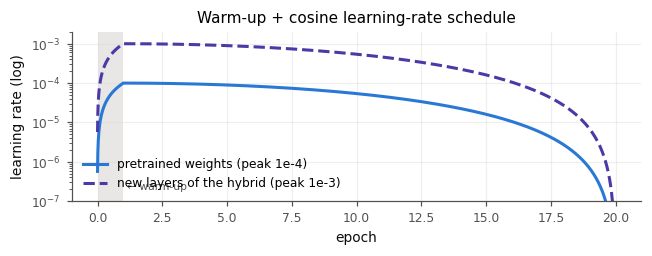

In [3]:
# Learning-rate schedule used by every model (5,600 training images / batch 32 = 175 steps per epoch)
steps_per_epoch = math.ceil(5600 / BATCH_SIZE)
total_steps = MAX_EPOCHS * steps_per_epoch
steps = np.arange(total_steps)
factor = np.array([lr_factor(s, steps_per_epoch, total_steps) for s in steps])

fig, ax = plt.subplots(figsize=(6.0, 2.4))
ax.plot(steps / steps_per_epoch, LR * factor, color="#2a78d6", lw=2, label="pretrained weights (peak 1e-4)")
ax.plot(steps / steps_per_epoch, LR_NEW_LAYERS * factor, color="#4a3aa7", lw=2, ls="--",
        label="new layers of the hybrid (peak 1e-3)")
ax.axvspan(0, WARMUP_EPOCHS, color="#d9d8d4", alpha=0.6, lw=0)
ax.text(WARMUP_EPOCHS + 0.15, 2e-7, "← warm-up", fontsize=7, color="#52514e")
ax.set(yscale="log", ylim=(1e-7, 2e-3), xlabel="epoch", ylabel="learning rate (log)",
       title="Warm-up + cosine learning-rate schedule")
ax.legend(frameon=False, loc="lower left")
ax.grid(alpha=0.4)
plt.tight_layout()
save_figure(fig, "fig0_lr_schedule")

## 3. Data

**Kvasir v2** (Pogorelov et al., 2017) contains 8,000 endoscopic images of the gastrointestinal tract, collected at
Vestre Viken Health Trust (Norway) and annotated by endoscopists: 1,000 images for each of 8 classes covering
anatomical landmarks (*z-line, pylorus, cecum*), pathological findings (*esophagitis, polyps, ulcerative colitis*)
and endoscopic procedures (*dyed-lifted polyps, dyed resection margins*). Resolutions range from 720×576 to
1920×1072 px.

**Where to process the 2.5 GB archive.** It is downloaded **directly inside Colab** to the VM's local disk:
* Colab downloads from simula.no at datacenter speed (a few minutes), and anyone can reproduce the notebook
  without access to the author's Drive or computer.
* The images are **not** read from Google Drive: reading 8,000 small files through the Drive mount is very slow
  (each file is a network request).
* After the first run the resized images are saved as a single `.npz` cache (≈1.5 GB) in Drive, which later runs
  load in seconds.

*Technical note:* the simula.no server does not send its intermediate TLS certificate, so the default certificate
check can fail. In that case the intermediate certificate is fetched from the certificate authority (Sectigo)
and added to the trusted store, so the download is still fully verified.

In [4]:
INTERMEDIATE_CA = "http://crt.sectigo.com/SectigoPublicServerAuthenticationCADVR36.crt"   # listed in the server certificate


def open_url(request):
    try:
        return urllib.request.urlopen(request, timeout=60)
    except urllib.error.URLError as err:
        if not isinstance(err.reason, ssl.SSLCertVerificationError):
            raise
    try:
        import certifi
        context = ssl.create_default_context(cafile=certifi.where())
    except ImportError:
        context = ssl.create_default_context()
    der = urllib.request.urlopen(INTERMEDIATE_CA, timeout=60).read()
    context.load_verify_locations(cadata=ssl.DER_cert_to_PEM_cert(der))
    return urllib.request.urlopen(request, timeout=60, context=context)


def download(url, path, max_attempts=20):
    """Download with resume: the server sometimes closes the connection early without an error,
    so the size is checked and the missing bytes are requested again (HTTP Range)."""
    part, total = path + ".part", None
    for _ in range(max_attempts):
        done = os.path.getsize(part) if os.path.exists(part) else 0
        if total is not None and done >= total:
            break
        request = urllib.request.Request(url, headers={"Range": f"bytes={done}-"} if done else {})
        try:
            with open_url(request) as response:
                if done and response.status != 206:                 # server ignored the range: start over
                    done = 0
                    open(part, "wb").close()
                total = done + int(response.headers["Content-Length"])
                with open(part, "ab") as f:
                    next_report = (done / total // 0.1 + 1) * 0.1
                    while chunk := response.read(16 << 20):
                        f.write(chunk)
                        done += len(chunk)
                        if done / total >= next_report:
                            print(f"  {done / 2**30:.2f} / {total / 2**30:.2f} GB")
                            next_report += 0.1
        except (urllib.error.URLError, ConnectionError, TimeoutError) as err:
            print("  connection interrupted, resuming:", err)
    if total is None or os.path.getsize(part) != total:
        raise RuntimeError("Download incomplete; run the cell again to resume it")
    os.rename(part, path)                                         # only a complete download gets the final name


def download_and_extract():
    zip_path = os.path.join(SCRATCH_DIR, "kvasir-dataset-v2.zip")
    if not os.path.exists(zip_path):
        print("Downloading", DATASET_URL)
        download(DATASET_URL, zip_path)
    print("Extracting...")
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(os.path.dirname(DATA_DIR))


start = time.time()
if not os.path.exists(CACHE_FILE) and not all(os.path.isdir(os.path.join(DATA_DIR, c)) for c in CLASSES):
    download_and_extract()
    print(f"Download + extraction: {time.time() - start:.0f} s")

  0.23 / 2.32 GB
  0.47 / 2.32 GB
  0.70 / 2.32 GB
  0.94 / 2.32 GB
  1.17 / 2.32 GB
  1.41 / 2.32 GB
  1.62 / 2.32 GB
  1.86 / 2.32 GB
  2.09 / 2.32 GB
  2.32 / 2.32 GB
Extracting...
Download + extraction: 442 s


In [5]:
def load_image(path):
    with Image.open(path) as img:
        original_size = img.size
        img.draft("RGB", (CACHE_SIZE, CACHE_SIZE))          # decode the JPEG directly at reduced scale (much faster)
        return np.asarray(img.convert("RGB").resize((CACHE_SIZE, CACHE_SIZE), Image.LANCZOS)), original_size


if os.path.exists(CACHE_FILE):
    cache = np.load(CACHE_FILE)
    images, labels, ids, original_sizes = (cache[k] for k in ("images", "labels", "ids", "original_sizes"))
    print("Loaded cache", CACHE_FILE)
else:
    paths, labels = [], []
    for i, c in enumerate(CLASSES):
        files = sorted(f for f in os.listdir(os.path.join(DATA_DIR, c)) if f.lower().endswith(".jpg"))[:PER_CLASS]
        paths += [os.path.join(DATA_DIR, c, f) for f in files]
        labels += [i] * len(files)
    start = time.time()
    with ThreadPoolExecutor(os.cpu_count() or 4) as pool:
        loaded = list(pool.map(load_image, paths))
    images = np.stack([img for img, _ in loaded])
    original_sizes = np.array([size for _, size in loaded])
    labels = np.array(labels)
    ids = np.array([os.path.relpath(p, DATA_DIR) for p in paths])
    tmp = CACHE_FILE.replace(".npz", ".tmp.npz")
    np.savez(tmp, images=images, labels=labels, ids=ids, original_sizes=original_sizes)
    os.replace(tmp, CACHE_FILE)                            # the cache only exists once it is complete
    print(f"Decoded and resized {len(images)} images in {time.time() - start:.0f} s -> {CACHE_FILE}")

print("images:", images.shape, images.dtype, f"({images.nbytes / 2**30:.2f} GB)")

Decoded and resized 8000 images in 19 s -> /content/drive/MyDrive/kvasir_dl_final/cache/kvasir_v2_256px.npz
images: (8000, 256, 256, 3) uint8 (1.46 GB)


### 3.1 Exploration
The dataset is **perfectly balanced** (1,000 images per class), so no re-weighting or re-sampling is needed. If it
were imbalanced, the options would be a class-weighted cross-entropy, oversampling the minority classes, or a
focal loss — and macro-F1 (§6) would still be the right metric because it weighs every class equally.

class,dyed-lifted-polyps,dyed-resection-margins,esophagitis,normal-cecum,normal-pylorus,normal-z-line,polyps,ulcerative-colitis
images,1000,1000,1000,1000,1000,1000,1000,1000


,original size,images
0,720×576,5137
1,1280×1024,2122
2,1920×1072,734
3,1350×1080,3
4,1350×1064,3
5,576×576,1


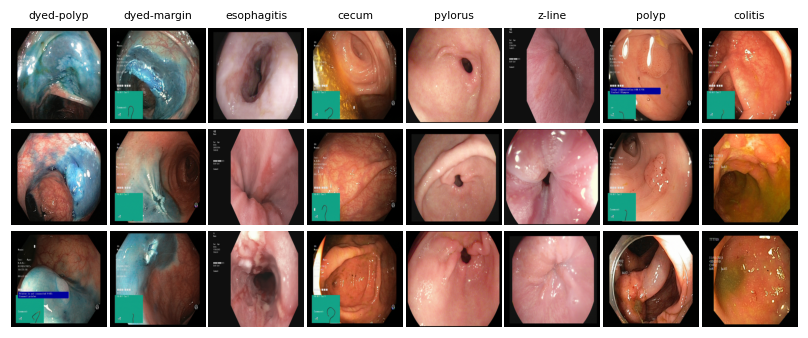

In [6]:
counts = pd.DataFrame({"class": CLASSES, "images": np.bincount(labels, minlength=NUM_CLASSES)})
sizes = pd.Series([f"{w}×{h}" for w, h in original_sizes]).value_counts().rename_axis("original size").reset_index(name="images")
display(counts.set_index("class").T)
display(sizes.head(8))
save_table(counts, "dataset_class_counts", index=False)
save_table(sizes, "dataset_original_sizes", index=False)

rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(3, NUM_CLASSES, figsize=(7.2, 3.0))
for j in range(NUM_CLASSES):
    for i, k in enumerate(rng.choice(np.flatnonzero(labels == j), 3, replace=False)):
        axes[i, j].imshow(images[k])
        axes[i, j].axis("off")
    axes[0, j].set_title(LABELS[j], fontsize=7)
plt.tight_layout(pad=0.2)
save_figure(fig, "fig_dataset_examples")

### 3.2 A known bias: the green *ScopeGuide* box
Many Kvasir images contain a teal-green box in the lower-left corner: the **ScopeGuide** display that shows the 3-D
position of the colonoscope. It only exists in **colonoscopies** (lower GI tract), never in gastroscopies (upper GI:
esophagus, z-line, pylorus), so its presence is strongly correlated with the class — a model could learn
"box → colon class" instead of learning anatomy (a *shortcut*; Geirhos et al., 2020).

The cell below locates the box from the data (teal pixels: G > 100, G − R > 60 and G > B; the reddish mucosa and the
blue dye never satisfy all three), measures in which fraction of each class it appears and stores its bounding box.
§13 then hides it and measures how much each model depended on it.

ScopeGuide box (y0, y1, x0, x1) in the 256 px images: (167, 256, 0, 92); area = 12.5 % of the image; present in 38.3 % of the images


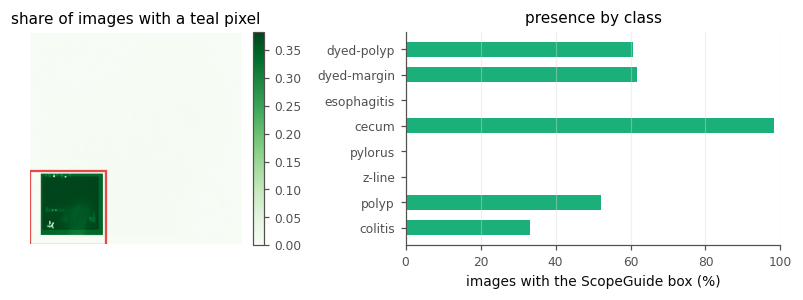

In [7]:
def green_fraction(batch):
    x = batch.astype(np.int16)
    r, g, b = x[..., 0], x[..., 1], x[..., 2]
    return (g > 100) & (g - r > 60) & (g > b)          # the teal-green of the ScopeGuide display


green_freq = np.zeros((CACHE_SIZE, CACHE_SIZE))
for start in range(0, len(images), 500):
    green_freq += green_fraction(images[start:start + 500]).sum(0)
green_freq /= len(images)

half = CACHE_SIZE // 2
region = green_freq[half:, :half]                       # lower-left quadrant
if region.max() > 0.02:
    ys, xs = np.nonzero(region > 0.5 * region.max())
    BOX = (int(half + ys.min() - 4), CACHE_SIZE, 0, int(min(half, xs.max() + 5)))   # (y0, y1, x0, x1), 4 px margin
else:                                                  # (e.g. tiny smoke-test subsets): typical position
    BOX = (int(0.65 * CACHE_SIZE), CACHE_SIZE, 0, int(0.36 * CACHE_SIZE))
y0, y1, x0, x1 = BOX
# The share of teal pixels inside the box region is bimodal (~0 % or ~65 %): 10 % separates the two groups
has_box = np.array([green_fraction(images[k, y0:y1, x0:x1]).mean() > 0.10 for k in range(len(images))])
print(f"ScopeGuide box (y0, y1, x0, x1) in the 256 px images: {BOX}; "
      f"area = {100 * (y1 - y0) * (x1 - x0) / CACHE_SIZE**2:.1f} % of the image; "
      f"present in {100 * has_box.mean():.1f} % of the images")

box_by_class = pd.DataFrame({"class": CLASSES,
                             "images with box (%)": [100 * has_box[labels == j].mean() for j in range(NUM_CLASSES)]})
save_table(box_by_class, "scopeguide_by_class", index=False)

fig, (ax_map, ax_bar) = plt.subplots(1, 2, figsize=(7.2, 2.8), gridspec_kw={"width_ratios": [1, 1.6]})
im = ax_map.imshow(green_freq, cmap="Greens", vmin=0)
ax_map.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="#e34948", lw=1.5))
ax_map.set_title("share of images with a teal pixel")
ax_map.axis("off")
fig.colorbar(im, ax=ax_map, fraction=0.046)
ax_bar.barh(LABELS, box_by_class["images with box (%)"], color="#1baf7a", height=0.6)
ax_bar.invert_yaxis()
ax_bar.set(xlabel="images with the ScopeGuide box (%)", xlim=(0, 100), title="presence by class")
ax_bar.grid(axis="x", alpha=0.4)
plt.tight_layout()
save_figure(fig, "fig_scopeguide_bias")

### 3.3 Stratified split (70 / 15 / 15)
The split is **stratified** (same class proportions in every subset) and fixed by the seed. The validation set is
used for early stopping and for choosing the ensemble; the **test set is only used once, for the final numbers**.
The image-to-split assignment is saved to `tables/split.csv` so it can be verified.

In [8]:
index = np.arange(len(labels))
trainval_idx, test_idx = train_test_split(index, test_size=SPLIT[2], stratify=labels, random_state=SEED)
train_idx, val_idx = train_test_split(trainval_idx, test_size=SPLIT[1] / (SPLIT[0] + SPLIT[1]),
                                      stratify=labels[trainval_idx], random_state=SEED)
SPLITS = {"train": np.sort(train_idx), "val": np.sort(val_idx), "test": np.sort(test_idx)}

split_counts = pd.DataFrame({s: np.bincount(labels[i], minlength=NUM_CLASSES) for s, i in SPLITS.items()}, index=CLASSES)
split_counts.loc["total"] = split_counts.sum()
display(split_counts.T)
pd.DataFrame([(ids[k], CLASSES[labels[k]], s) for s, idx in SPLITS.items() for k in idx],
             columns=["image", "class", "split"]).to_csv(os.path.join(TABLE_DIR, "split.csv"), index=False)

# The whole dataset (uint8, ≈1.5 GB) lives on the GPU: batches are sliced there, with no CPU data-loading bottleneck
X = {s: torch.from_numpy(images[i]).permute(0, 3, 1, 2).contiguous().to(device) for s, i in SPLITS.items()}
Y = {s: torch.from_numpy(labels[i]).to(device) for s, i in SPLITS.items()}
y_true = {s: labels[i] for s, i in SPLITS.items()}

,dyed-lifted-polyps,dyed-resection-margins,esophagitis,normal-cecum,normal-pylorus,normal-z-line,polyps,ulcerative-colitis,total
train,700,700,700,700,700,700,700,700,5600
val,150,150,150,150,150,150,150,150,1200
test,150,150,150,150,150,150,150,150,1200


## 4. Preprocessing and data augmentation

| Step | Train | Validation / test | Why |
|---|---|---|---|
| Resize | 256×256 (once, cached) | 256×256 | Uniform size; a 32 px margin is left for random cropping |
| Crop | random 224×224 position | center 224×224 | Small translations; evaluation is deterministic |
| Flips | horizontal and vertical (p = 0.5 each) | — | An endoscope has no canonical orientation: a flipped image is still a valid image |
| Rotation | uniform in ±15° | — | Rotation of the scope around its axis |
| Brightness / contrast | ×[0.9, 1.1] each | — | Illumination changes between procedures and distances to the mucosa |
| **Hue / saturation** | **not changed** | — | **Color is diagnostic**: the blue indigo-carmine dye separates *dyed-polyps* from *polyps*, and redness indicates esophagitis or colitis. Changing the hue would destroy the label information |
| Normalization | mean/std of each model's pretraining | same | ImageNet statistics for the CNNs, (0.5, 0.5, 0.5) for the ViT (its AugReg pretraining used that). Done *inside* each model wrapper, so the pipeline is shared |

All of it runs **on the GPU** with a single `affine_grid` + `grid_sample` per batch (crop + flips + rotation at
once). Colab VMs have only a few CPU cores, and classic per-image PIL augmentation becomes the bottleneck at 224 px.

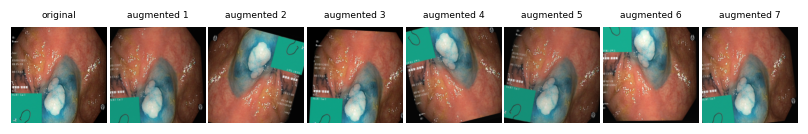

In [9]:
def augment(x, res=IMG_SIZE):
    """Train view. x: (B, 3, 256, 256) uint8 on the GPU -> (B, 3, res, res) float in [0, 1]."""
    x = x.float() / 255
    b = x.size(0)
    rand = lambda: torch.rand(b, device=x.device)
    angle = (2 * rand() - 1) * math.radians(15)
    flip_x = torch.where(rand() < 0.5, -1.0, 1.0)
    flip_y = torch.where(rand() < 0.5, -1.0, 1.0)
    scale = IMG_SIZE / CACHE_SIZE                                 # a 224 crop out of 256
    shift_x, shift_y = (2 * rand() - 1) * (1 - scale), (2 * rand() - 1) * (1 - scale)
    cos, sin = angle.cos(), angle.sin()
    theta = torch.stack([torch.stack([scale * cos * flip_x, -scale * sin * flip_y, shift_x], 1),
                         torch.stack([scale * sin * flip_x, scale * cos * flip_y, shift_y], 1)], 1)
    grid = F.affine_grid(theta, (b, 3, IMG_SIZE, IMG_SIZE), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    contrast = 1 + 0.1 * (2 * rand() - 1).view(-1, 1, 1, 1)
    brightness = 1 + 0.1 * (2 * rand() - 1).view(-1, 1, 1, 1)
    mean = x.mean((1, 2, 3), keepdim=True)
    x = (((x - mean) * contrast + mean) * brightness).clamp(0, 1)
    return resize(x, res)


def eval_view(x, res=IMG_SIZE):
    """Validation/test view: deterministic center crop."""
    m = (CACHE_SIZE - IMG_SIZE) // 2
    return resize(x[:, :, m:m + IMG_SIZE, m:m + IMG_SIZE].float() / 255, res)


def resize(x, res):
    return x if res == IMG_SIZE else F.interpolate(x, size=(res, res), mode="bilinear", antialias=True, align_corners=False)


def batches(split, batch_size, generator=None):
    """Mini-batches of (uint8 images, labels); shuffled when a generator is given."""
    n = len(Y[split])
    order = torch.randperm(n, generator=generator) if generator is not None else torch.arange(n)
    for start in range(0, n, batch_size):
        idx = order[start:start + batch_size].to(device)
        yield X[split][idx], Y[split][idx]


set_seed(SEED)
example = X["train"][:1].repeat(8, 1, 1, 1)
views = torch.cat([eval_view(example[:1]), augment(example[1:])]).permute(0, 2, 3, 1).cpu().numpy()
fig, axes = plt.subplots(1, 8, figsize=(7.2, 1.2))
for k, ax in enumerate(axes):
    ax.imshow(views[k])
    ax.set_title("original" if k == 0 else f"augmented {k}", fontsize=6)
    ax.axis("off")
plt.tight_layout(pad=0.2)
save_figure(fig, "fig_augmentation_examples")

## 5. Models

### 5.1 Why these variants

**ResNet** (He et al., 2016) — chosen: **ResNet-50**

| Variant | Parameters | GMACs (224 px) | ImageNet top-1 (torchvision v1) |
|---|---|---|---|
| ResNet-18 | 11.7 M | 1.8 | 69.8 % |
| **ResNet-50** ✔ | 25.6 M | 4.1 | 76.1 % |
| ResNet-101 | 44.5 M | 7.8 | 77.4 % |
| ResNet-152 | 60.2 M | 11.5 | 78.3 % |

ResNet-50 is the knee of the curve: it is the first depth that uses *bottleneck* blocks, and going to 101 or 152
layers costs 2–3× more compute for +1–2 ImageNet points — gains that do not transfer to a 5,600-image dataset, where
the extra depth mostly adds over-fitting risk. It is also the most common CNN baseline in the Kvasir literature,
which makes our numbers comparable. Weights: `resnet50.tv2_in1k` (torchvision's improved training recipe, 80.9 %).

**EfficientNet** (Tan & Le, 2019) — chosen: **EfficientNet-B0**

| Variant | Native resolution | Parameters | GMACs |
|---|---|---|---|
| **B0** ✔ | 224 | 5.3 M | 0.39 |
| B3 | 300 | 12 M | 1.8 |
| B4 | 380 | 19 M | 4.2 |
| B7 | 600 | 66 M | 37 |

EfficientNet scales depth, width **and input resolution** together (*compound scaling*). Using B3–B7 at 224 px
would break its design, and using them at their native resolution would break our protocol (every model must see
the same 224 px input). B0 is the only variant native at 224 px, and it gives the most interesting contrast with
ResNet-50: similar ImageNet accuracy with **5× fewer parameters and 10× fewer MACs**.

**Vision Transformer** (Dosovitskiy et al., 2021) — chosen: **ViT-S/16** pretrained on ImageNet-21k

| Variant | Parameters | GMACs | Comment |
|---|---|---|---|
| ViT-Ti/16 | 5.7 M | 1.1 | Too little capacity |
| **ViT-S/16** ✔ | 22 M | 4.6 | **Compute-matched with ResNet-50** |
| ViT-B/16 | 86 M | 17.6 | 4× slower, heavily over-parameterized for 5,600 images |
| Swin-T | 28 M | 4.5 | Local windows + hierarchy make it CNN-like, which blurs the CNN-vs-Transformer contrast (the hybrid covers that middle ground) |

ViT-S/16 has about the same compute as ResNet-50, so their comparison isolates **the architecture** (convolution vs.
self-attention) rather than the budget. Transformers lack the locality bias of convolutions and therefore need far
more pretraining data, which is why the AugReg weights pretrained on **ImageNet-21k** (14 M images; Steiner et al.,
2022) are used: `vit_small_patch16_224.augreg_in21k_ft_in1k`.

**Hybrid (built in this notebook)** — ResNet-50 stages 1–3 + Transformer encoder
```
image 224×224 → ResNet-50 stem + stages 1–3 (pretrained) → feature map 14×14×1024
             → 1×1 conv projection 1024→384 → 196 tokens + [CLS] token + learned position embeddings
             → 4 pre-norm Transformer layers (6 heads, MLP 1536, dropout 0.1) → LayerNorm → linear head (8 classes)
```
* **Why**: the CNN extracts *local* texture (vessels, mucosa, dye) with a strong inductive bias that is data-efficient;
  self-attention then relates *distant* regions, which matters for anatomical landmarks (pylorus, z-line, cecum) that
  are recognized by global structure. This is the hybrid design of the original ViT paper and of the TransUNet
  encoder (Chen et al., 2021).
* **Why cut after stage 3**: 14×14 = 196 tokens give attention something to relate and produce usable attention
  maps; stage 4 would leave only 7×7 = 49 coarse tokens, and its weights are the most ImageNet-specific.
* **Controlled comparison**: Hybrid vs. ResNet-50 answers exactly *"what does replacing stage 4 + global pooling with
  self-attention buy?"*
* The new layers start from scratch, so they get a 10× learning rate (§2).

In [10]:
TIMM_NAMES = {"ResNet-50": "resnet50.tv2_in1k",
              "EfficientNet-B0": "efficientnet_b0.ra_in1k",
              "ViT-S/16": "vit_small_patch16_224.augreg_in21k_ft_in1k"}
HYBRID = "Hybrid R50+Transformer"
MAIN_MODELS = [*TIMM_NAMES, HYBRID]
SHORT = {"ResNet-50": "R50", "EfficientNet-B0": "B0", "ViT-S/16": "ViT", HYBRID: "Hybrid"}
COLORS = {"ResNet-50": "#2a78d6", "EfficientNet-B0": "#eb6834", "ViT-S/16": "#1baf7a", HYBRID: "#4a3aa7"}
ENSEMBLE_COLOR = "#52514e"


class Normalized(nn.Module):
    """Applies the normalization each network was pretrained with; inputs are images in [0, 1]."""
    def __init__(self, net, mean, std):
        super().__init__()
        self.net = net
        self.register_buffer("mean", torch.tensor(mean).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(std).view(1, 3, 1, 1))

    def forward(self, x):
        return self.net((x - self.mean) / self.std)


class Block(nn.Module):
    """Pre-norm Transformer encoder layer. Attention is computed explicitly when `keep_attention` is set,
    so its maps can be read for the interpretability analysis (§12)."""
    def __init__(self, dim, heads, mlp_ratio=4, dropout=0.1):
        super().__init__()
        self.heads, self.dropout = heads, dropout
        self.norm1, self.norm2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.qkv, self.proj = nn.Linear(dim, 3 * dim), nn.Linear(dim, dim)
        self.mlp = nn.Sequential(nn.Linear(dim, mlp_ratio * dim), nn.GELU(), nn.Dropout(dropout),
                                 nn.Linear(mlp_ratio * dim, dim), nn.Dropout(dropout))
        self.drop = nn.Dropout(dropout)
        self.keep_attention, self.attention = False, None

    def forward(self, x):
        b, n, d = x.shape
        q, k, v = self.qkv(self.norm1(x)).reshape(b, n, 3, self.heads, d // self.heads).permute(2, 0, 3, 1, 4)
        if self.keep_attention:
            attn = (q @ k.transpose(-2, -1) * (d // self.heads) ** -0.5).softmax(-1)
            self.attention = attn.detach()
            out = attn @ v
        else:
            out = F.scaled_dot_product_attention(q, k, v, dropout_p=self.dropout if self.training else 0.0)
        x = x + self.drop(self.proj(out.transpose(1, 2).reshape(b, n, d)))
        return x + self.mlp(self.norm2(x))


class ResNetTransformerHybrid(nn.Module):
    def __init__(self, pretrained=True, dim=384, depth=4, heads=6, grid=IMG_SIZE // 16):
        super().__init__()
        r = timm.create_model(TIMM_NAMES["ResNet-50"], pretrained=pretrained)
        self.pretrained_cfg = r.pretrained_cfg
        self.cnn = nn.Sequential(r.conv1, r.bn1, r.act1, r.maxpool, r.layer1, r.layer2, r.layer3)   # stride 16
        self.proj = nn.Conv2d(1024, dim, kernel_size=1)
        self.cls = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos = nn.Parameter(torch.zeros(1, 1 + grid * grid, dim))
        nn.init.trunc_normal_(self.cls, std=0.02)
        nn.init.trunc_normal_(self.pos, std=0.02)
        self.blocks = nn.ModuleList([Block(dim, heads) for _ in range(depth)])
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, NUM_CLASSES)

    def new_parameters(self):
        """Everything that is not the pretrained CNN (trained with LR_NEW_LAYERS)."""
        cnn = {id(p) for p in self.cnn.parameters()}
        return [p for p in self.parameters() if id(p) not in cnn]

    def forward(self, x):
        tokens = self.proj(self.cnn(x)).flatten(2).transpose(1, 2)          # (B, 196, dim)
        tokens = torch.cat([self.cls.expand(len(x), -1, -1), tokens], 1) + self.pos
        for block in self.blocks:
            tokens = block(tokens)
        return self.head(self.norm(tokens[:, 0]))                           # classify from the [CLS] token


def build_model(name, pretrained=True):
    if name == HYBRID:
        net = ResNetTransformerHybrid(pretrained)
    else:
        net = timm.create_model(TIMM_NAMES[name], pretrained=pretrained, num_classes=NUM_CLASSES)
    return Normalized(net, net.pretrained_cfg["mean"], net.pretrained_cfg["std"])


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())


@torch.no_grad()
def count_gmacs(model, res=IMG_SIZE):
    """Multiply-accumulate operations for one image (the 'FLOPs' usually quoted in papers are MACs)."""
    model.eval()
    with FlopCounterMode(display=False) as counter:
        model(torch.zeros(1, 3, res, res, device=next(model.parameters()).device))
    return counter.get_total_flops() / 2e9


static_cost = []
for name in MAIN_MODELS:
    model = build_model(name).to(device)
    trainable_new = sum(p.numel() for p in model.net.new_parameters()) if name == HYBRID else 0
    static_cost.append({"Model": name, "Parameters (M)": count_parameters(model) / 1e6,
                        "Randomly initialized (M)": (trainable_new or sum(p.numel() for p in model.net.get_classifier().parameters())) / 1e6,
                        "GMACs @224": count_gmacs(model),
                        "Normalization mean": tuple(round(v, 3) for v in model.mean.flatten().tolist())})
    del model
static_cost = pd.DataFrame(static_cost).set_index("Model")
display(static_cost.round(3))
save_table(static_cost.drop(columns="Normalization mean"), "static_cost")

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

,Parameters (M),Randomly initialized (M),GMACs @224,Normalization mean
Model,,,,
ResNet-50,23.524,0.016,4.087,"(0.485, 0.456, 0.406)"
EfficientNet-B0,4.018,0.010,0.385,"(0.485, 0.456, 0.406)"
ViT-S/16,21.669,0.003,4.599,"(0.5, 0.5, 0.5)"
Hybrid R50+Transformer,16.115,7.571,4.869,"(0.485, 0.456, 0.406)"


## 6. Metrics and success criteria

| Aspect | Metric | Why |
|---|---|---|
| Performance (**primary**) | **Macro-F1** on the test set | F1 = 2·precision·recall / (precision + recall) per class, averaged with equal weight over the 8 classes: a model cannot hide a weak class behind strong ones |
| Performance | Accuracy, per-class precision / recall / F1, confusion matrix | Accuracy is intuitive (chance = 12.5 %); the per-class view shows *which* classes fail |
| Uncertainty | 95 % **bootstrap** confidence intervals (1,000 resamples of the 1,200 test images, the same resamples for every model) | Shows how much a score depends on the particular test images |
| Significance | Exact **McNemar** test between pairs of models | Tests whether two models make significantly different errors on the same images |
| Computational cost | Parameters, GMACs, training time, peak GPU memory, throughput (ms/img, batch 64) and latency (ms, batch 1) | Training cost, deployment cost and real-time suitability (an endoscopy video runs at 25–30 fps ⇒ < 33 ms/frame) |
| Convergence | Best epoch, epochs run, epochs needed to reach 95 % of the best validation macro-F1 | "Ease of convergence" requested by the project |
| Interpretability | Grad-CAM / attention rollout; share of the map's mass inside the ScopeGuide box | Do the models look at the mucosa or at artifacts? |
| Generalization | Macro-F1 drop when the ScopeGuide box is masked | Robustness to a dataset-specific shortcut |

**Success criteria (defined before training):**
1. Every model reaches a test macro-F1 ≥ **0.90** (published transfer-learning results on Kvasir v2 are in the low-to-mid 90 % range).
2. Differences between models are only claimed when the McNemar test gives p < 0.05.
3. The best model must not lose more than 0.02 macro-F1 when the ScopeGuide box is masked (it relies on anatomy, not on the artifact).

In [11]:
def scores(y, pred):
    return accuracy_score(y, pred), f1_score(y, pred, average="macro", labels=range(NUM_CLASSES), zero_division=0)


def macro_f1_fast(y, pred):
    cm = np.bincount(y * NUM_CLASSES + pred, minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)
    denom = cm.sum(0) + cm.sum(1)
    return np.mean(np.where(denom > 0, 2 * np.diag(cm) / np.maximum(denom, 1), 0.0))


BOOT = np.random.default_rng(0).integers(0, len(SPLITS["test"]), size=(N_BOOTSTRAP, len(SPLITS["test"])))


def bootstrap_f1(pred, y=None):
    """Macro-F1 of each bootstrap resample of the test set (paired: same resamples for every model)."""
    y = y_true["test"] if y is None else y
    return np.array([macro_f1_fast(y[i], pred[i]) for i in BOOT])


def mcnemar(pred_a, pred_b, y=None):
    y = y_true["test"] if y is None else y
    a_only, b_only = int(np.sum((pred_a == y) & (pred_b != y))), int(np.sum((pred_a != y) & (pred_b == y)))
    p = stats.binomtest(min(a_only, b_only), a_only + b_only, 0.5).pvalue if a_only + b_only else 1.0
    return a_only, b_only, p

## 7. Training protocol

One function, `train()`, is used for every model and every sensitivity run:

* **Loss**: cross-entropy with label smoothing 0.1. **Optimizer**: AdamW (weight decay 0.05, not applied to biases,
  normalization parameters, position embeddings or class tokens). For the hybrid, the new layers get a 10× learning rate.
* **Schedule**: 1 epoch of linear warm-up, then cosine decay (updated after every batch).
* **Mixed precision** (bf16 on L4/A100, fp16 + GradScaler on T4) and gradient clipping at norm 1.0.
* After each epoch: validation loss, accuracy and macro-F1. **Early stopping** when the validation macro-F1 has not
  improved for 4 epochs; the weights of the best epoch are restored.
* Measured: training time (incl. validation), peak GPU memory used by the model (the dataset tensors are excluded),
  throughput and single-image latency, MACs.
* Saved to `results/runs/`: a JSON with the configuration, metrics, per-epoch history and the softmax probabilities
  on validation and test (used by the ensemble), plus the weights of the 4 main models (used in §12–13).
  **If a run's JSON already exists, it is loaded instead of retrained** — this is what makes the notebook resumable.

In [12]:
def autocast():
    return torch.autocast(device.type, dtype=AMP_DTYPE, enabled=USE_AMP)


def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()


@torch.no_grad()
def predict(model, split, res=IMG_SIZE, transform=None):
    """Softmax probabilities and mean cross-entropy on a split (deterministic center crop)."""
    model.eval()
    probs, loss = [], 0.0
    for xb, yb in batches(split, 128):
        if transform is not None:
            xb = transform(xb)
        with autocast():
            logits = model(eval_view(xb, res)).float()
        loss += F.cross_entropy(logits, yb, reduction="sum").item()
        probs.append(logits.softmax(1).cpu())
    return torch.cat(probs).numpy(), loss / len(Y[split])


@torch.no_grad()
def latency_ms(model, res, batch):
    """Inference time per image (ms) for a given batch size."""
    model.eval()
    x = torch.rand(batch, 3, res, res, device=device)
    repeats = 20 if device.type == "cuda" else 2
    with autocast():
        for _ in range(3):
            model(x)
        sync()
        start = time.perf_counter()
        for _ in range(repeats):
            model(x)
        sync()
    return 1000 * (time.perf_counter() - start) / (repeats * batch)


def param_groups(model, lr):
    new = {id(p) for p in model.net.new_parameters()} if isinstance(model.net, ResNetTransformerHybrid) else set()
    groups = {}
    for name, p in model.named_parameters():
        is_new = id(p) in new
        no_decay = p.ndim <= 1 or name.split(".")[-1] in ("pos_embed", "cls_token", "pos", "cls")
        groups.setdefault((is_new, no_decay), []).append(p)
    return [{"params": ps, "lr": lr * (LR_NEW_LAYERS / LR if is_new else 1), "weight_decay": 0.0 if no_decay else WEIGHT_DECAY}
            for (is_new, no_decay), ps in groups.items()]


def train(model_name, tag, lr=LR, batch_size=BATCH_SIZE, res=IMG_SIZE, augmentation=True, pretrained=True):
    set_seed(SEED)
    if device.type == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        memory_before = torch.cuda.memory_allocated()
    model = build_model(model_name, pretrained).to(device)
    optimizer = torch.optim.AdamW(param_groups(model, lr))
    steps_per_epoch = math.ceil(len(Y["train"]) / batch_size)
    total_steps = MAX_EPOCHS * steps_per_epoch
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: lr_factor(s, steps_per_epoch, total_steps))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and AMP_DTYPE == torch.float16)
    criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    generator = torch.Generator().manual_seed(SEED)

    history = {k: [] for k in ("train_loss", "val_loss", "val_acc", "val_f1", "lr", "epoch_time")}
    best_f1, best_epoch, best_state, bad_epochs = -1.0, 0, None, 0
    sync()
    train_start = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        epoch_start, running = time.perf_counter(), 0.0
        for xb, yb in batches("train", batch_size, generator):
            xb = augment(xb, res) if augmentation else eval_view(xb, res)
            with autocast():
                loss = criterion(model(xb).float(), yb)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            running += loss.item() * len(yb)
        val_probs, val_loss = predict(model, "val", res)
        sync()
        acc, f1 = scores(y_true["val"], val_probs.argmax(1))
        for key, value in zip(history, (running / len(Y["train"]), val_loss, acc, f1, scheduler.get_last_lr()[0],
                                        time.perf_counter() - epoch_start)):
            history[key].append(value)
        print(f"[{tag}] epoch {epoch:2d}  train loss {history['train_loss'][-1]:.4f}  val loss {val_loss:.4f}  "
              f"val acc {100 * acc:5.2f}%  val macro-F1 {f1:.4f}  ({history['epoch_time'][-1]:.0f} s)")
        if f1 > best_f1 + 1e-4:
            best_f1, best_epoch, bad_epochs = f1, epoch, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                print(f"[{tag}] early stopping: no improvement for {PATIENCE} epochs (best epoch {best_epoch})")
                break
    train_time = time.perf_counter() - train_start
    peak_mb = (torch.cuda.max_memory_allocated() - memory_before) / 2**20 if device.type == "cuda" else float("nan")

    model.load_state_dict(best_state)
    val_probs, _ = predict(model, "val", res)
    test_probs, _ = predict(model, "test", res)
    test_acc, test_f1 = scores(y_true["test"], test_probs.argmax(1))
    val_f1 = np.array(history["val_f1"])
    result = {"Model": tag, "Base model": model_name, "Pretrained": pretrained, "LR": lr, "Batch size": batch_size,
              "Resolution": res, "Augmentation": augmentation,
              "Parameters": count_parameters(model), "GMACs": count_gmacs(model, res),
              "Train time (s)": train_time, "Time per epoch (s)": train_time / len(val_f1),
              "Peak GPU memory (MB)": peak_mb,
              "Throughput (ms/img)": latency_ms(model, res, 64), "Latency batch 1 (ms)": latency_ms(model, res, 1),
              "Best epoch": best_epoch, "Epochs run": len(val_f1),
              "Epochs to 95% of best": int(np.argmax(val_f1 >= 0.95 * best_f1)) + 1,
              "Val macro-F1": best_f1, "Test accuracy (%)": 100 * test_acc, "Test macro-F1": test_f1, "GPU": GPU_NAME}
    print(f"[{tag}] TEST accuracy {100 * test_acc:.2f}%  macro-F1 {test_f1:.4f}  | train time {train_time:.0f} s")
    return result, history, val_probs, test_probs, model


def run_path(tag):
    return os.path.join(RUNS_DIR, re.sub(r"[^A-Za-z0-9]+", "_", tag).strip("_"))


def run_or_load(model_name, tag=None, keep_weights=False, **config):
    """Train a run, or load it if it already finished in a previous session (resumable notebook)."""
    tag = tag or model_name
    path = run_path(tag)
    if os.path.exists(path + ".json"):
        with open(path + ".json") as f:
            saved = json.load(f)
        print(f"[{tag}] loaded from a previous session (trained on {saved['result']['GPU']})")
        if saved["result"]["GPU"] != GPU_NAME:
            print(f"   warning: this session uses {GPU_NAME}; training times are only comparable on the same GPU")
        return saved["result"], saved["history"], np.array(saved["val_probs"]), np.array(saved["test_probs"])
    result, history, val_p, test_p, model = train(model_name, tag, **config)
    if keep_weights:
        torch.save(model.state_dict(), path + ".pt")
    with open(path + ".json", "w") as f:
        json.dump({"result": result, "history": history, "config": config,
                   "val_probs": val_p.round(6).tolist(), "test_probs": test_p.round(6).tolist()}, f)
    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return result, history, val_p, test_p


def load_trained(name):
    model = build_model(name, pretrained=False)
    model.load_state_dict(torch.load(run_path(name) + ".pt", map_location="cpu"))
    return model.to(device).eval()

## 8. Training the four models
Same protocol, same seed, same data order. Each line shows one epoch; the best epoch's weights are kept.

In [13]:
results, histories, val_probs, test_probs = {}, {}, {}, {}
for name in MAIN_MODELS:
    results[name], histories[name], val_probs[name], test_probs[name] = run_or_load(name, keep_weights=True)

COST_COLUMNS = ["Parameters", "GMACs", "Train time (s)", "Time per epoch (s)", "Peak GPU memory (MB)",
                "Throughput (ms/img)", "Latency batch 1 (ms)", "Best epoch", "Epochs run", "Epochs to 95% of best"]
display(pd.DataFrame(results.values()).set_index("Model")[["Val macro-F1", "Test accuracy (%)", "Test macro-F1", *COST_COLUMNS]].round(4))

[ResNet-50] epoch  1  train loss 1.4754  val loss 0.4175  val acc 87.58%  val macro-F1 0.8752  (16 s)
[ResNet-50] epoch  2  train loss 0.6964  val loss 0.3505  val acc 90.50%  val macro-F1 0.9049  (15 s)
[ResNet-50] epoch  3  train loss 0.6339  val loss 0.3451  val acc 89.67%  val macro-F1 0.8958  (15 s)
[ResNet-50] epoch  4  train loss 0.5979  val loss 0.3147  val acc 91.92%  val macro-F1 0.9194  (15 s)
[ResNet-50] epoch  5  train loss 0.5782  val loss 0.2668  val acc 92.92%  val macro-F1 0.9289  (15 s)
[ResNet-50] epoch  6  train loss 0.5624  val loss 0.2901  val acc 92.75%  val macro-F1 0.9274  (15 s)
[ResNet-50] epoch  7  train loss 0.5422  val loss 0.2948  val acc 91.83%  val macro-F1 0.9182  (15 s)
[ResNet-50] epoch  8  train loss 0.5268  val loss 0.3019  val acc 93.08%  val macro-F1 0.9307  (15 s)
[ResNet-50] epoch  9  train loss 0.5191  val loss 0.3134  val acc 92.17%  val macro-F1 0.9214  (15 s)
[ResNet-50] epoch 10  train loss 0.5129  val loss 0.3147  val acc 92.33%  val macr

,Val macro-F1,Test accuracy (%),Test macro-F1,Parameters,GMACs,Train time (s),Time per epoch (s),Peak GPU memory (MB),Throughput (ms/img),Latency batch 1 (ms),Best epoch,Epochs run,Epochs to 95% of best
Model,,,,,,,,,,,,,
ResNet-50,0.9350,92.0833,0.9207,23524424,4.0872,245.9313,15.3707,1909.2646,0.7383,8.8564,12,16,2
EfficientNet-B0,0.9232,91.2500,0.9124,4017796,0.3845,209.7304,11.0384,1491.6138,0.3940,11.3457,15,19,3
ViT-S/16,0.9466,93.5833,0.9358,21668744,4.5985,190.3465,9.5173,1545.4136,0.4463,7.1960,19,20,3
Hybrid R50+Transformer,0.9095,90.6667,0.9062,16114632,4.8685,162.2114,16.2211,2088.8164,0.8140,10.3595,6,10,2


## 9. Hyperparameter sensitivity — *what happens if we change them?*

**Design: one factor at a time.** Each run starts from the exact configuration of a main model and changes **a
single** hyperparameter, so any difference can be attributed to that change. EfficientNet-B0 is used because it is
the cheapest model (≈3–5 min per run). One extra run trains **ViT-S from scratch** to test the central argument of
the analysis: without the locality bias of convolutions, a Transformer depends on large-scale pretraining.

| Run | Changed factor | Prediction (from §2) |
|---|---|---|
| B0 · LR 1e-5 | learning rate 1e-4 → 1e-5 | slower convergence, lower F1 within 20 epochs |
| B0 · LR 1e-3 | learning rate 1e-4 → 1e-3 | noisier curves, pretrained features partially destroyed |
| B0 · batch 128 | batch size 32 → 128 (same LR) | 4× fewer updates → slower convergence |
| B0 · 64 px | resolution 224 → 64 px | clear drop: fine detail is lost |
| B0 · no augmentation | augmentation on → off | faster fit of the training set, more over-fitting |
| B0 · from scratch | ImageNet weights → random init | large drop: 5,600 images are not enough to learn good features |
| ViT-S · from scratch | ImageNet-21k weights → random init | **much** larger drop than the CNN: no inductive bias |

*Note:* the from-scratch runs keep the fine-tuning learning rate (1e-4) to respect the one-factor-at-a-time design;
a tuned from-scratch recipe would use a higher LR and many more epochs, so these runs show the value of pretraining
**under the same budget**.

In [14]:
SENSITIVITY = {
    "B0 · LR 1e-5": ("EfficientNet-B0", "learning rate 1e-4 → 1e-5", {"lr": 1e-5}),
    "B0 · LR 1e-3": ("EfficientNet-B0", "learning rate 1e-4 → 1e-3", {"lr": 1e-3}),
    "B0 · batch 128": ("EfficientNet-B0", "batch size 32 → 128", {"batch_size": 128}),
    "B0 · 64 px": ("EfficientNet-B0", "resolution 224 → 64 px", {"res": 64}),
    "B0 · no augmentation": ("EfficientNet-B0", "augmentation on → off", {"augmentation": False}),
    "B0 · from scratch": ("EfficientNet-B0", "ImageNet weights → random init", {"pretrained": False}),
    "ViT-S · from scratch": ("ViT-S/16", "ImageNet-21k weights → random init", {"pretrained": False}),
}
sens_results, sens_histories, sens_test_probs = {}, {}, {}
for tag, (base, _, config) in SENSITIVITY.items():
    sens_results[tag], sens_histories[tag], _, sens_test_probs[tag] = run_or_load(base, tag=tag, **config)

boot_cache = {}
def boot_of(key, probs):
    if key not in boot_cache:
        boot_cache[key] = bootstrap_f1(probs.argmax(1))
    return boot_cache[key]

rows = []
for tag, (base, change, _) in SENSITIVITY.items():
    r, rb = sens_results[tag], results[base]
    delta = boot_of(tag, sens_test_probs[tag]) - boot_of(base, test_probs[base])
    rows.append({"Run": tag, "Changed factor": change, "Test macro-F1": r["Test macro-F1"],
                 "Δ macro-F1 vs. baseline": r["Test macro-F1"] - rb["Test macro-F1"],
                 "Δ CI low": np.percentile(delta, 2.5), "Δ CI high": np.percentile(delta, 97.5),
                 "Best epoch": r["Best epoch"], "Epochs run": r["Epochs run"], "Train time (s)": r["Train time (s)"],
                 "GMACs": r["GMACs"]})
sensitivity_table = pd.DataFrame(rows).set_index("Run")
print("Baselines: EfficientNet-B0 macro-F1 = %.4f | ViT-S/16 macro-F1 = %.4f"
      % (results["EfficientNet-B0"]["Test macro-F1"], results["ViT-S/16"]["Test macro-F1"]))
display(sensitivity_table.round(4))
save_table(sensitivity_table, "sensitivity")

[B0 · LR 1e-5] epoch  1  train loss 3.1997  val loss 2.2459  val acc 34.00%  val macro-F1 0.3310  (11 s)
[B0 · LR 1e-5] epoch  2  train loss 1.8256  val loss 1.1597  val acc 60.50%  val macro-F1 0.6013  (11 s)
[B0 · LR 1e-5] epoch  3  train loss 1.3492  val loss 0.8343  val acc 70.50%  val macro-F1 0.7034  (11 s)
[B0 · LR 1e-5] epoch  4  train loss 1.1682  val loss 0.7074  val acc 74.92%  val macro-F1 0.7477  (11 s)
[B0 · LR 1e-5] epoch  5  train loss 1.0895  val loss 0.6161  val acc 78.17%  val macro-F1 0.7804  (11 s)
[B0 · LR 1e-5] epoch  6  train loss 1.0483  val loss 0.5841  val acc 79.08%  val macro-F1 0.7895  (11 s)
[B0 · LR 1e-5] epoch  7  train loss 1.0029  val loss 0.5513  val acc 81.08%  val macro-F1 0.8105  (11 s)
[B0 · LR 1e-5] epoch  8  train loss 0.9642  val loss 0.5386  val acc 81.67%  val macro-F1 0.8163  (11 s)
[B0 · LR 1e-5] epoch  9  train loss 0.9307  val loss 0.5165  val acc 82.08%  val macro-F1 0.8200  (11 s)
[B0 · LR 1e-5] epoch 10  train loss 0.9397  val loss 0.

,Changed factor,Test macro-F1,Δ macro-F1 vs. baseline,Δ CI low,Δ CI high,Best epoch,Epochs run,Train time (s),GMACs
Run,,,,,,,,,
B0 · LR 1e-5,learning rate 1e-4 → 1e-5,0.8058,-0.1066,-0.1292,-0.0859,17,20,220.7934,0.3845
B0 · LR 1e-3,learning rate 1e-4 → 1e-3,0.9274,0.0151,0.0015,0.0296,10,14,154.4918,0.3845
B0 · batch 128,batch size 32 → 128,0.8980,-0.0144,-0.0285,-0.0015,11,15,173.0744,0.3845
B0 · 64 px,resolution 224 → 64 px,0.8593,-0.0531,-0.0741,-0.0337,17,20,170.7935,0.0320
B0 · no augmentation,augmentation on → off,0.9132,0.0008,-0.0129,0.0133,14,18,194.9280,0.3845
B0 · from scratch,ImageNet weights → random init,0.6536,-0.2587,-0.2866,-0.2332,11,15,165.7688,0.3845
ViT-S · from scratch,ImageNet-21k weights → random init,0.7490,-0.1867,-0.2107,-0.1623,20,20,189.8841,4.5985


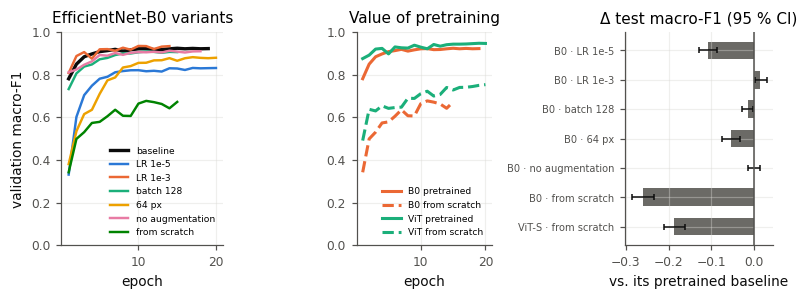

In [15]:
SENS_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
fig, (ax_b0, ax_vit, ax_delta) = plt.subplots(1, 3, figsize=(7.2, 2.8), gridspec_kw={"width_ratios": [1.2, 1, 1.1]})
ax_b0.plot(range(1, len(histories["EfficientNet-B0"]["val_f1"]) + 1), histories["EfficientNet-B0"]["val_f1"],
           color="#0b0b0b", lw=2.2, label="baseline")
for color, tag in zip(SENS_COLORS, [t for t in SENSITIVITY if t.startswith("B0")]):
    h = sens_histories[tag]["val_f1"]
    ax_b0.plot(range(1, len(h) + 1), h, color=color, lw=1.6, label=tag.replace("B0 · ", ""))
ax_b0.set(title="EfficientNet-B0 variants", xlabel="epoch", ylabel="validation macro-F1", ylim=(0, 1))
ax_b0.legend(frameon=False, fontsize=6, loc="lower right")
for name, scratch, color in [("EfficientNet-B0", "B0 · from scratch", COLORS["EfficientNet-B0"]),
                             ("ViT-S/16", "ViT-S · from scratch", COLORS["ViT-S/16"])]:
    ax_vit.plot(range(1, len(histories[name]["val_f1"]) + 1), histories[name]["val_f1"], color=color, lw=2, label=f"{SHORT[name]} pretrained")
    h = sens_histories[scratch]["val_f1"]
    ax_vit.plot(range(1, len(h) + 1), h, color=color, lw=2, ls="--", label=f"{SHORT[name]} from scratch")
ax_vit.set(title="Value of pretraining", xlabel="epoch", ylim=(0, 1))
ax_vit.legend(frameon=False, fontsize=6, loc="lower right")
y = np.arange(len(sensitivity_table))
d = sensitivity_table["Δ macro-F1 vs. baseline"].values
ax_delta.barh(y, d, color="#6b6a66", height=0.6)
ax_delta.errorbar(d, y, xerr=[d - sensitivity_table["Δ CI low"].values, sensitivity_table["Δ CI high"].values - d],
                  fmt="none", ecolor="#0b0b0b", elinewidth=1, capsize=2)
ax_delta.axvline(0, color="#52514e", lw=1)
ax_delta.set_yticks(y, sensitivity_table.index, fontsize=6.5)
ax_delta.invert_yaxis()
ax_delta.set(title="Δ test macro-F1 (95 % CI)", xlabel="vs. its pretrained baseline")
for a in (ax_b0, ax_vit, ax_delta):
    a.grid(alpha=0.4)
plt.tight_layout()
save_figure(fig, "fig_sensitivity")

## 10. Ensemble (soft voting)

Soft voting averages the softmax probabilities of its members and predicts the most probable class. It only helps
when the members make errors on **different** images, which is more likely between different families (CNN vs.
Transformer) than between two similar CNNs.

**Honest selection:** all 11 possible combinations of the 4 models (6 pairs, 4 triplets, 1 quadruplet) are scored on
the **validation** set; the best one (ties → fewer members, i.e. cheaper) is chosen and only then evaluated on the
test set. The test column below is shown for transparency only; it was not used for the choice. The ensemble needs
no extra training, but its training and inference cost is the **sum** of its members.

In [16]:
combos = [c for k in range(2, len(MAIN_MODELS) + 1) for c in itertools.combinations(MAIN_MODELS, k)]
ensemble_rows = []
for members in combos:
    pv = np.mean([val_probs[m] for m in members], 0)
    pt = np.mean([test_probs[m] for m in members], 0)
    ensemble_rows.append({"Members": " + ".join(SHORT[m] for m in members), "Size": len(members),
                          "Val macro-F1": scores(y_true["val"], pv.argmax(1))[1],
                          "Test macro-F1 (not used for selection)": scores(y_true["test"], pt.argmax(1))[1]})
ensemble_table = pd.DataFrame(ensemble_rows).sort_values(["Val macro-F1", "Size"], ascending=[False, True]).reset_index(drop=True)
display(ensemble_table.round(4))
save_table(ensemble_table, "ensemble_selection", index=False)

ENSEMBLE_MEMBERS = combos[[" + ".join(SHORT[m] for m in c) for c in combos].index(ensemble_table.loc[0, "Members"])]
ENSEMBLE = "Ensemble " + "+".join(SHORT[m] for m in ENSEMBLE_MEMBERS)
val_probs[ENSEMBLE] = np.mean([val_probs[m] for m in ENSEMBLE_MEMBERS], 0)
test_probs[ENSEMBLE] = np.mean([test_probs[m] for m in ENSEMBLE_MEMBERS], 0)
acc, f1 = scores(y_true["test"], test_probs[ENSEMBLE].argmax(1))
summed = ["Parameters", "GMACs", "Train time (s)", "Throughput (ms/img)", "Latency batch 1 (ms)"]
results[ENSEMBLE] = {"Model": ENSEMBLE, **{k: sum(results[m][k] for m in ENSEMBLE_MEMBERS) for k in summed},
                     "Val macro-F1": ensemble_table.loc[0, "Val macro-F1"], "Test accuracy (%)": 100 * acc, "Test macro-F1": f1}
COLORS[ENSEMBLE] = ENSEMBLE_COLOR
print(f"Selected on validation: {ENSEMBLE}  ->  test accuracy {100 * acc:.2f}%, macro-F1 {f1:.4f}")

,Members,Size,Val macro-F1,Test macro-F1 (not used for selection)
0,ViT + Hybrid,2,0.9474,0.9383
1,R50 + ViT,2,0.9457,0.9374
2,R50 + B0 + ViT,3,0.9450,0.9332
3,B0 + ViT,2,0.9449,0.9357
4,R50 + ViT + Hybrid,3,0.9433,0.9315
5,R50 + B0 + ViT + Hybrid,4,0.9400,0.9348
6,B0 + ViT + Hybrid,3,0.9399,0.9366
7,R50 + B0,2,0.9357,0.9323
8,R50 + B0 + Hybrid,3,0.9332,0.9248
9,R50 + Hybrid,2,0.9316,0.9257


Selected on validation: Ensemble ViT+Hybrid  ->  test accuracy 93.83%, macro-F1 0.9383


## 11. Results

### 11.1 Summary table
Point estimates with **95 % bootstrap confidence intervals** over the test set. Cost columns of the ensemble are the
sum of its members. Training time and latency were measured on the GPU printed in §1.

In [17]:
ALL = MAIN_MODELS + [ENSEMBLE]
preds = {m: test_probs[m].argmax(1) for m in ALL}
boot_f1 = {m: boot_of(m, test_probs[m]) for m in ALL}
boot_acc = {m: 100 * (y_true["test"][BOOT] == preds[m][BOOT]).mean(1) for m in ALL}

summary = pd.DataFrame([results[m] for m in ALL]).set_index("Model")
summary[["F1 CI low", "F1 CI high", "Acc CI low", "Acc CI high"]] = [
    [*np.percentile(boot_f1[m], [2.5, 97.5]), *np.percentile(boot_acc[m], [2.5, 97.5])] for m in ALL]
ORDER = list(summary["Test macro-F1"].sort_values(ascending=False).index)
summary = summary.loc[ORDER]
summary.drop(columns=["Base model", "GPU"], errors="ignore").to_csv(os.path.join(TABLE_DIR, "results_full.csv"))

fmt = lambda col, f: summary[col].map(lambda v: "—" if pd.isna(v) else f.format(v))
paper_table = pd.DataFrame({
    "Accuracy (%)": [f"{a:.2f} [{l:.2f}, {h:.2f}]" for a, l, h in summary[["Test accuracy (%)", "Acc CI low", "Acc CI high"]].values],
    "Macro-F1": [f"{a:.3f} [{l:.3f}, {h:.3f}]" for a, l, h in summary[["Test macro-F1", "F1 CI low", "F1 CI high"]].values],
    "Params (M)": (summary["Parameters"] / 1e6).map("{:.1f}".format),
    "GMACs": fmt("GMACs", "{:.2f}"),
    "Train time (s)": fmt("Train time (s)", "{:.0f}"),
    "Peak mem. (MB)": fmt("Peak GPU memory (MB)", "{:.0f}"),
    "Latency (ms)": fmt("Latency batch 1 (ms)", "{:.2f}"),
    "Best / run epochs": [("—" if pd.isna(b) else f"{b:.0f} / {e:.0f}") for b, e in summary[["Best epoch", "Epochs run"]].values],
    "Epochs to 95 %": fmt("Epochs to 95% of best", "{:.0f}"),
}, index=ORDER)
display(paper_table)
save_table(paper_table, "results_main")
print(f"Chance level: 12.5 % accuracy. GPU: {GPU_NAME}")

,Accuracy (%),Macro-F1,Params (M),GMACs,Train time (s),Peak mem. (MB),Latency (ms),Best / run epochs,Epochs to 95 %
Ensemble ViT+Hybrid,"93.83 [92.50, 95.25]","0.938 [0.925, 0.952]",37.8,9.47,353,—,17.56,—,—
ViT-S/16,"93.58 [92.25, 94.92]","0.936 [0.923, 0.949]",21.7,4.60,190,1545,7.20,19 / 20,3
ResNet-50,"92.08 [90.58, 93.58]","0.921 [0.906, 0.935]",23.5,4.09,246,1909,8.86,12 / 16,2
EfficientNet-B0,"91.25 [89.67, 92.83]","0.912 [0.897, 0.927]",4.0,0.38,210,1492,11.35,15 / 19,3
Hybrid R50+Transformer,"90.67 [89.00, 92.42]","0.906 [0.890, 0.923]",16.1,4.87,162,2089,10.36,6 / 10,2


Chance level: 12.5 % accuracy. GPU: NVIDIA L4


### 11.2 Figure 1 — Test performance with 95 % confidence intervals

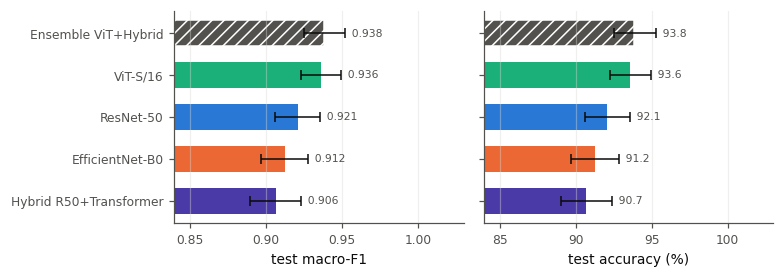

In [18]:
def bar_with_ci(ax, names, values, low, high, fmt):
    y = np.arange(len(names))
    bars = ax.barh(y, values, color=[COLORS[n] for n in names], height=0.62)
    for bar, n in zip(bars, names):
        if n == ENSEMBLE:
            bar.set_hatch("///")
            bar.set_edgecolor("white")
    ax.errorbar(values, y, xerr=[np.array(values) - low, high - np.array(values)], fmt="none", ecolor="#0b0b0b",
                elinewidth=1, capsize=3)
    for yi, v, h in zip(y, values, high):
        ax.text(h, yi, "  " + fmt.format(v), va="center", fontsize=7, color="#52514e")
    ax.set_yticks(y, names)
    ax.grid(axis="x", alpha=0.4)


fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.6), sharey=True)
bar_with_ci(axes[0], ORDER, summary["Test macro-F1"].values, summary["F1 CI low"].values, summary["F1 CI high"].values, "{:.3f}")
bar_with_ci(axes[1], ORDER, summary["Test accuracy (%)"].values, summary["Acc CI low"].values, summary["Acc CI high"].values, "{:.1f}")
lo = max(0, summary["F1 CI low"].min() - 0.05)
axes[0].set(xlabel="test macro-F1", xlim=(lo, 1.03))
axes[1].set(xlabel="test accuracy (%)", xlim=(100 * lo, 103))
axes[0].invert_yaxis()
plt.tight_layout()
save_figure(fig, "fig1_performance_ci")

### 11.3 Figure 2 — Convergence
Training loss (with label smoothing its minimum is ≈0.5, not 0), validation loss and validation macro-F1 per epoch.
The dot marks the best epoch (the weights that were kept).

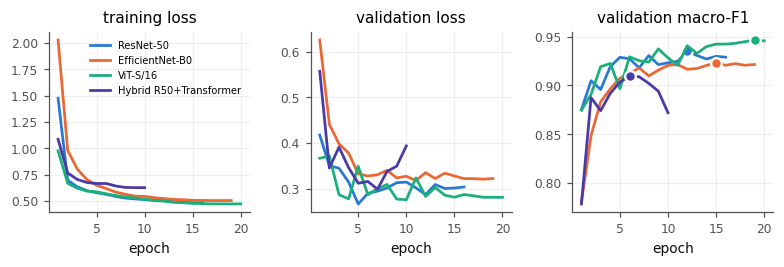

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.5))
for name in MAIN_MODELS:
    h = histories[name]
    epochs = np.arange(1, len(h["val_f1"]) + 1)
    axes[0].plot(epochs, h["train_loss"], color=COLORS[name], lw=1.8, label=name)
    axes[1].plot(epochs, h["val_loss"], color=COLORS[name], lw=1.8)
    axes[2].plot(epochs, h["val_f1"], color=COLORS[name], lw=1.8)
    best = results[name]["Best epoch"]
    axes[2].plot(best, h["val_f1"][best - 1], "o", ms=7, color=COLORS[name], mec="white", mew=1.5)
for ax, title in zip(axes, ["training loss", "validation loss", "validation macro-F1"]):
    ax.set(title=title, xlabel="epoch")
    ax.grid(alpha=0.4)
axes[0].legend(frameon=False, fontsize=6.5)
plt.tight_layout()
save_figure(fig, "fig2_convergence")

### 11.4 Figure 3 — Performance vs. computational cost
Up-and-left is better. The ensemble (square) costs the sum of its members. Error bars = 95 % CI of the macro-F1. Note that **MACs and wall-clock time do
not agree**: depthwise convolutions (EfficientNet) do few operations but are memory-bound on GPUs.

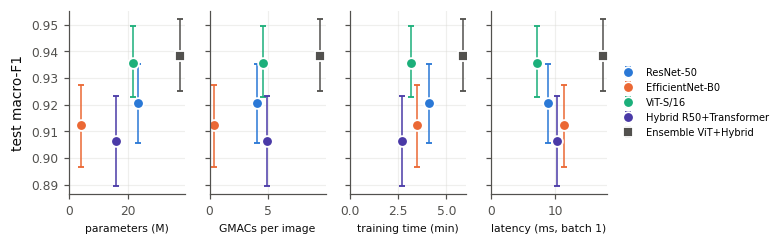

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(7.2, 2.3), sharey=True)
for ax, col, scale, label in [(axes[0], "Parameters", 1e6, "parameters (M)"), (axes[1], "GMACs", 1, "GMACs per image"),
                              (axes[2], "Train time (s)", 60, "training time (min)"),
                              (axes[3], "Latency batch 1 (ms)", 1, "latency (ms, batch 1)")]:
    for name in ALL:
        x, yv = summary.loc[name, col] / scale, summary.loc[name, "Test macro-F1"]
        ax.errorbar(x, yv, yerr=[[yv - summary.loc[name, "F1 CI low"]], [summary.loc[name, "F1 CI high"] - yv]],
                    fmt="s" if name == ENSEMBLE else "o", ms=7, color=COLORS[name], mec="white", mew=1.2,
                    elinewidth=1, capsize=2, label=name)
    ax.set_xlim(0, None)
    ax.set_xlabel(label, fontsize=7)
    ax.grid(alpha=0.4)
axes[0].set_ylabel("test macro-F1")
axes[-1].legend(frameon=False, loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=6.5)
plt.tight_layout()
save_figure(fig, "fig3_performance_vs_cost")

### 11.5 Figure 4 — Per-class F1 and Figure 5 — Confusion matrices

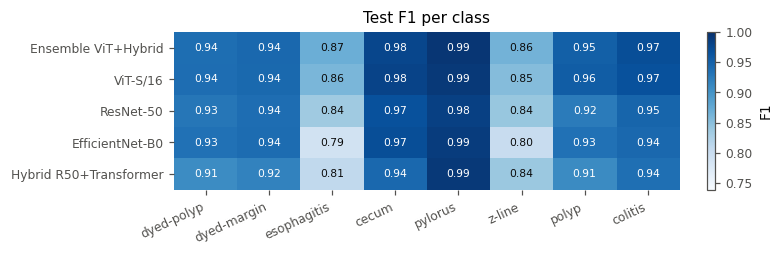

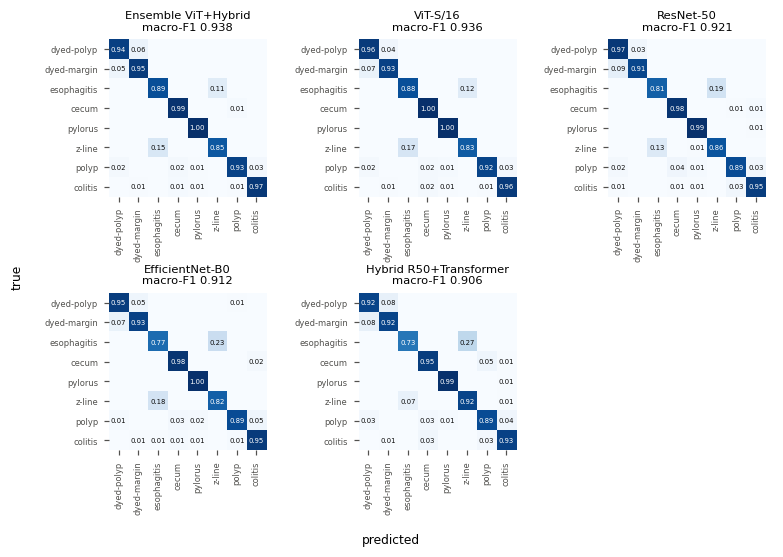

In [21]:
per_class = {}
for m in ALL:
    p, r, f, _ = precision_recall_fscore_support(y_true["test"], preds[m], labels=range(NUM_CLASSES), zero_division=0)
    per_class[m] = pd.DataFrame({"precision": p, "recall": r, "F1": f}, index=CLASSES)
pd.concat(per_class, names=["model", "class"]).round(4).to_csv(os.path.join(TABLE_DIR, "per_class_metrics.csv"))
pc = np.array([per_class[m]["F1"].values for m in ORDER])
save_table(pd.DataFrame(pc, index=ORDER, columns=LABELS).round(4), "per_class_f1")

fig, ax = plt.subplots(figsize=(7.2, 2.4))
im = ax.imshow(pc, cmap="Blues", vmin=max(0, pc.min() - 0.05), vmax=1, aspect="auto")
for i in range(len(ORDER)):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{pc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if pc[i, j] > (pc.min() + 1) / 2 else "#0b0b0b")
ax.set_xticks(range(NUM_CLASSES), LABELS, rotation=25, ha="right")
ax.set_yticks(range(len(ORDER)), ORDER)
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, fraction=0.025, label="F1")
ax.set_title("Test F1 per class")
plt.tight_layout()
save_figure(fig, "fig4_per_class_f1")

fig, axes = plt.subplots(2, 3, figsize=(7.2, 5.0))
for ax, name in zip(axes.flat, ORDER):
    cm = confusion_matrix(y_true["test"], preds[name], labels=range(NUM_CLASSES), normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            if cm[i, j] >= 0.005:
                ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=4.5,
                        color="white" if cm[i, j] > 0.6 else "#0b0b0b")
    ax.set_xticks(range(NUM_CLASSES), LABELS, rotation=90, fontsize=5.5)
    ax.set_yticks(range(NUM_CLASSES), LABELS, fontsize=5.5)
    ax.set_title(f"{name}\nmacro-F1 {summary.loc[name, 'Test macro-F1']:.3f}", fontsize=7.5)
    ax.spines[:].set_visible(False)
for ax in axes.flat[len(ORDER):]:
    ax.axis("off")
fig.supxlabel("predicted", fontsize=8)
fig.supylabel("true", fontsize=8)
plt.tight_layout()
save_figure(fig, "fig5_confusion_matrices")

### 11.6 Statistical significance — pairwise McNemar tests
*A only* = test images that model A classifies correctly and B does not (and vice versa). p < 0.05 means the two
models make significantly different errors; otherwise the difference in accuracy could be due to chance.

In [22]:
rows = []
for a, b in itertools.combinations(ORDER, 2):
    a_only, b_only, p = mcnemar(preds[a], preds[b])
    rows.append({"Model A": a, "Model B": b, "A only correct": a_only, "B only correct": b_only,
                 "Δ accuracy (pp)": round(100 * ((preds[a] == y_true["test"]).mean() - (preds[b] == y_true["test"]).mean()), 2),
                 "p (McNemar)": p, "Significant (p<0.05)": "yes" if p < 0.05 else "no"})
mcnemar_table = pd.DataFrame(rows)
display(mcnemar_table.style.format({"p (McNemar)": "{:.2e}"}))
save_table(mcnemar_table, "mcnemar_tests", index=False)

# How different are the errors? (fraction of test images where both models of a pair are wrong / either is wrong)
wrong = {m: preds[m] != y_true["test"] for m in MAIN_MODELS}
overlap = pd.DataFrame([[(wrong[a] & wrong[b]).sum() / max(1, (wrong[a] | wrong[b]).sum()) for b in MAIN_MODELS] for a in MAIN_MODELS],
                       index=[SHORT[m] for m in MAIN_MODELS], columns=[SHORT[m] for m in MAIN_MODELS])
print("Error overlap (Jaccard of the misclassified test images; low = complementary models, good for ensembles):")
display(overlap.round(2))
save_table(overlap.round(3), "error_overlap")

,Model A,Model B,A only correct,B only correct,Δ accuracy (pp),p (McNemar),Significant (p<0.05)
0,Ensemble ViT+Hybrid,ViT-S/16,10,7,0.250000,6.29e-01,no
1,Ensemble ViT+Hybrid,ResNet-50,42,21,1.750000,1.11e-02,yes
2,Ensemble ViT+Hybrid,EfficientNet-B0,52,21,2.580000,3.71e-04,yes
3,Ensemble ViT+Hybrid,Hybrid R50+Transformer,58,20,3.170000,1.95e-05,yes
4,ViT-S/16,ResNet-50,44,26,1.500000,4.14e-02,yes
5,ViT-S/16,EfficientNet-B0,52,24,2.330000,1.76e-03,yes
6,ViT-S/16,Hybrid R50+Transformer,65,30,2.920000,4.25e-04,yes
7,ResNet-50,EfficientNet-B0,45,35,0.830000,3.14e-01,no
8,ResNet-50,Hybrid R50+Transformer,48,31,1.420000,7.12e-02,no
9,EfficientNet-B0,Hybrid R50+Transformer,52,45,0.580000,5.43e-01,no


Error overlap (Jaccard of the misclassified test images; low = complementary models, good for ensembles):


,R50,B0,ViT,Hybrid
R50,1.00,0.43,0.42,0.45
B0,0.43,1.00,0.41,0.38
ViT,0.42,0.41,1.00,0.33
Hybrid,0.45,0.38,0.33,1.00


## 12. Interpretability

* **Grad-CAM** (Selvaraju et al., 2017) for the CNNs: the gradients of the predicted class with respect to the last
  convolutional feature map weight its channels, giving a coarse map of the regions that drove the decision
  (7×7 for ResNet-50 and EfficientNet-B0, 14×14 for the hybrid's CNN part).
* **Attention rollout** (Abnar & Zuidema, 2020) for the Transformers: the attention matrices of all layers (averaged
  over heads, plus the identity for the residual connection) are multiplied to estimate how much each patch
  contributes to the [CLS] token. Used for ViT-S/16 (14×14 patches) and for the hybrid's Transformer layers.
* The hybrid is shown with **both** maps: what its CNN part detects and what its Transformer part attends to.

Figure 6 uses the same test image per class for every model (green title = correct prediction, red = wrong).

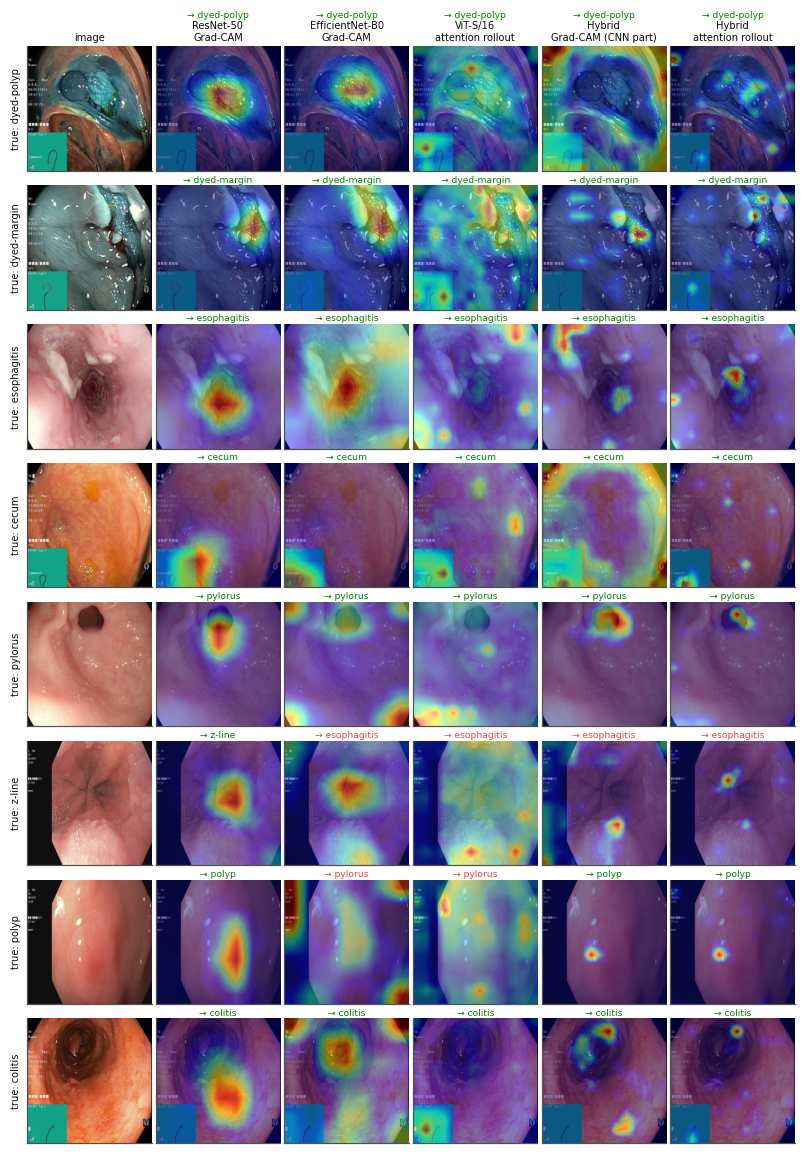

In [23]:
trained = {name: load_trained(name) for name in MAIN_MODELS}


def normalize_maps(m):
    m = m - m.flatten(1).min(1)[0].view(-1, 1, 1)
    return m / (m.flatten(1).max(1)[0].view(-1, 1, 1) + 1e-8)


def grad_cam(model, layer, x):
    store = {}

    def hook(module, inputs, output):
        store["act"] = output
        output.register_hook(lambda grad: store.__setitem__("grad", grad))

    handle = layer.register_forward_hook(hook)
    with torch.enable_grad():
        logits = model(x)
        pred = logits.argmax(1)
        model.zero_grad(set_to_none=True)
        logits.gather(1, pred[:, None]).sum().backward()
    handle.remove()
    weights = store["grad"].mean((2, 3), keepdim=True)                     # importance of each channel
    cam = F.relu((weights * store["act"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
    return normalize_maps(cam.detach()), pred.detach()


def attention_rollout(attentions, size):
    rollout = None
    for a in attentions:
        a = a.float().mean(1)                                               # average over heads
        a = a + torch.eye(a.size(-1), device=a.device)                       # residual connection
        a = a / a.sum(-1, keepdim=True)
        rollout = a if rollout is None else a @ rollout
    cls = rollout[:, 0, 1:]                                                 # [CLS] -> patches
    g = int(cls.size(1) ** 0.5)
    m = F.interpolate(cls.reshape(-1, 1, g, g), size=size, mode="bilinear", align_corners=False)[:, 0]
    return normalize_maps(m)


@torch.no_grad()
def vit_rollout(model, x):
    blocks, maps = model.net.blocks, []
    fused = [b.attn.fused_attn for b in blocks]
    for b in blocks:
        b.attn.fused_attn = False                                           # explicit softmax(QK^T) so it can be hooked
    hooks = [b.attn.attn_drop.register_forward_hook(lambda m, i, o: maps.append(i[0])) for b in blocks]
    pred = model(x).argmax(1)
    for h, b, f in zip(hooks, blocks, fused):
        h.remove()
        b.attn.fused_attn = f
    return attention_rollout(maps, x.shape[-2:]), pred


@torch.no_grad()
def hybrid_rollout(model, x):
    for b in model.net.blocks:
        b.keep_attention = True
    pred = model(x).argmax(1)
    maps = [b.attention for b in model.net.blocks]
    for b in model.net.blocks:
        b.keep_attention, b.attention = False, None
    return attention_rollout(maps, x.shape[-2:]), pred


EXPLAINERS = {   # column label -> (model, function returning (maps, predictions))
    "ResNet-50\nGrad-CAM": ("ResNet-50", lambda m, x: grad_cam(m, m.net.layer4, x)),
    "EfficientNet-B0\nGrad-CAM": ("EfficientNet-B0", lambda m, x: grad_cam(m, m.net.bn2, x)),
    "ViT-S/16\nattention rollout": ("ViT-S/16", vit_rollout),
    "Hybrid\nGrad-CAM (CNN part)": (HYBRID, lambda m, x: grad_cam(m, m.net.cnn[-1], x)),
    "Hybrid\nattention rollout": (HYBRID, hybrid_rollout),
}


def explain(test_positions, batch=32):
    """Maps and predictions of every explainer for the given test-set positions."""
    out = {}
    for label, (name, fn) in EXPLAINERS.items():
        maps, ps = [], []
        for s in range(0, len(test_positions), batch):
            x = eval_view(X["test"][torch.as_tensor(test_positions[s:s + batch], device=device)])
            m, p = fn(trained[name], x)
            maps.append(m.cpu())
            ps.append(p.cpu())
        out[label] = (torch.cat(maps).numpy(), torch.cat(ps).numpy())
    return out


def show_maps(positions, title_rows, name):
    maps = explain(positions)
    imgs = eval_view(X["test"][torch.as_tensor(positions, device=device)]).permute(0, 2, 3, 1).cpu().numpy()
    cols = ["image", *EXPLAINERS]
    fig, axes = plt.subplots(len(positions), len(cols), figsize=(7.2, 1.25 * len(positions) + 0.4), squeeze=False)
    for i, k in enumerate(positions):
        truth = y_true["test"][k]
        axes[i, 0].imshow(imgs[i])
        axes[i, 0].set_ylabel(title_rows[i], fontsize=6.5)
        for j, label in enumerate(EXPLAINERS, start=1):
            m, p = maps[label][0][i], maps[label][1][i]
            axes[i, j].imshow(imgs[i])
            axes[i, j].imshow(m, cmap="jet", alpha=0.45, vmin=0, vmax=1)
            axes[i, j].set_title(f"→ {LABELS[p]}", fontsize=6, color="#008300" if p == truth else "#e34948", pad=2)
        for j, col in enumerate(cols):
            axes[i, j].set_xticks([])
            axes[i, j].set_yticks([])
            if i == 0:
                axes[i, j].set_xlabel(col, fontsize=6.5)
                axes[i, j].xaxis.set_label_position("top")
    plt.tight_layout(pad=0.3)
    save_figure(fig, name)


one_per_class = [int(np.flatnonzero(y_true["test"] == c)[0]) for c in range(NUM_CLASSES)]
show_maps(one_per_class, [f"true: {LABELS[c]}" for c in range(NUM_CLASSES)], "fig6_interpretability")

### Figure 7 — Where do the models look when they fail?
The most frequent confusion over the four models is selected automatically, and up to four test images of that
confusion (those misclassified by the most models) are shown.

Most frequent confusion: true 'esophagitis' predicted as 'normal-z-line' (121 errors summed over the 4 models)


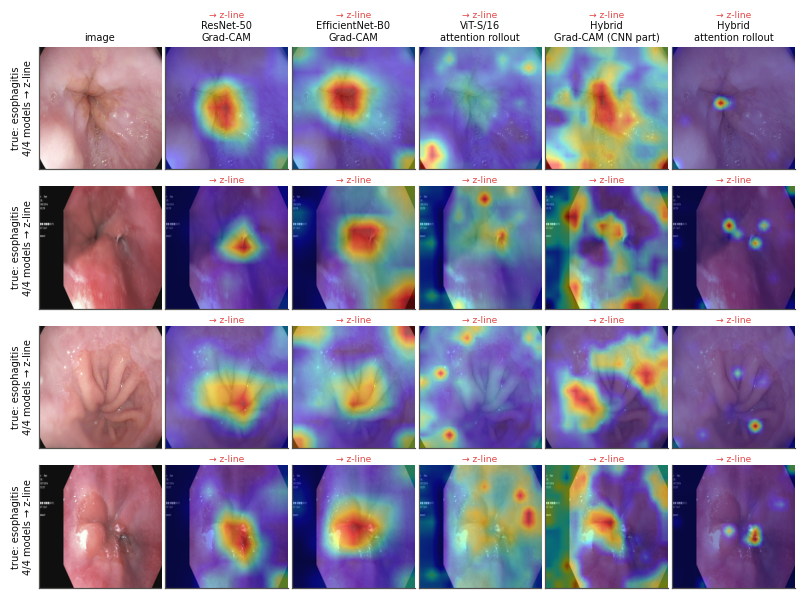

In [24]:
confusion_total = sum(confusion_matrix(y_true["test"], preds[m], labels=range(NUM_CLASSES)) for m in MAIN_MODELS)
np.fill_diagonal(confusion_total, 0)
true_c, pred_c = np.unravel_index(confusion_total.argmax(), confusion_total.shape)
print(f"Most frequent confusion: true '{CLASSES[true_c]}' predicted as '{CLASSES[pred_c]}' "
      f"({confusion_total[true_c, pred_c]} errors summed over the 4 models)")
n_wrong = sum((preds[m] == pred_c).astype(int) for m in MAIN_MODELS)
candidates = np.flatnonzero((y_true["test"] == true_c) & (n_wrong > 0))
error_examples = candidates[np.argsort(-n_wrong[candidates], kind="stable")][:4]
if len(error_examples):
    show_maps(list(error_examples), [f"true: {LABELS[true_c]}\n{n_wrong[k]}/4 models → {LABELS[pred_c]}" for k in error_examples],
              "fig7_failure_cases")

## 13. Shortcut test — do the models depend on the ScopeGuide box?

Two complementary measurements on the test set:
1. **Masking**: the box region found in §3.2 is painted black in every test image and the models are re-evaluated
   (no retraining). A model that relied on the box loses macro-F1 and changes many predictions.
2. **Where the maps look**: for the test images that contain the box, the share of each Grad-CAM / rollout map that
   falls inside the box, divided by the box's share of the image area. A ratio > 1 means the model looks at the box
   *more* than a uniform map would.

Note: because of the flip augmentation, during training the box appeared in all four corners, so a model could
have learned "a teal box anywhere" rather than a fixed position. Test images are never flipped, so masking the
lower-left corner removes the box completely at test time.

In [25]:
def mask_box(x):
    x = x.clone()
    x[:, :, y0:y1, x0:x1] = 0
    return x


masked_probs = {m: predict(trained[m], "test", transform=mask_box)[0] for m in MAIN_MODELS}
masked_probs[ENSEMBLE] = np.mean([masked_probs[m] for m in ENSEMBLE_MEMBERS], 0)
box_test = has_box[SPLITS["test"]]
rows = []
for m in ALL:
    masked_pred = masked_probs[m].argmax(1)
    delta = bootstrap_f1(masked_pred) - boot_f1[m]
    rows.append({"Model": m, "Macro-F1 original": summary.loc[m, "Test macro-F1"],
                 "Macro-F1 box masked": scores(y_true["test"], masked_pred)[1],
                 "Δ macro-F1": scores(y_true["test"], masked_pred)[1] - summary.loc[m, "Test macro-F1"],
                 "Δ CI low": np.percentile(delta, 2.5), "Δ CI high": np.percentile(delta, 97.5),
                 "Predictions changed (%)": 100 * (masked_pred != preds[m]).mean(),
                 "Changed, images with box (%)": 100 * (masked_pred != preds[m])[box_test].mean() if box_test.any() else np.nan})
shortcut_table = pd.DataFrame(rows).set_index("Model")

# Share of the explanation maps inside the box (224 px center-crop coordinates)
margin = (CACHE_SIZE - IMG_SIZE) // 2
cy0, cy1, cx0, cx1 = (int(np.clip(v - margin, 0, IMG_SIZE)) for v in BOX)
box_area = (cy1 - cy0) * (cx1 - cx0) / IMG_SIZE**2
box_positions = list(np.flatnonzero(box_test))
attention_ratio = {}
if box_positions and box_area > 0:
    maps = explain(box_positions)
    for label, (mp, _) in maps.items():
        inside = mp[:, cy0:cy1, cx0:cx1].sum((1, 2)) / (mp.sum((1, 2)) + 1e-8)
        attention_ratio[label.replace("\n", " ")] = inside.mean() / box_area
display(shortcut_table.round(4))
save_table(shortcut_table, "shortcut_test")
print(f"{len(box_positions)} test images contain the box; it covers {100 * box_area:.1f} % of the 224 px crop")
display(pd.Series(attention_ratio, name="map mass in box / box area").round(2).to_frame())
pd.Series(attention_ratio, name="ratio").to_csv(os.path.join(TABLE_DIR, "shortcut_map_ratio.csv"))

,Macro-F1 original,Macro-F1 box masked,Δ macro-F1,Δ CI low,Δ CI high,Predictions changed (%),"Changed, images with box (%)"
Model,,,,,,,
ResNet-50,0.9207,0.9067,-0.0139,-0.0242,-0.0042,3.3333,6.6372
EfficientNet-B0,0.9124,0.8847,-0.0277,-0.0418,-0.0129,6.1667,10.6195
ViT-S/16,0.9358,0.9105,-0.0253,-0.0376,-0.0133,4.5000,7.9646
Hybrid R50+Transformer,0.9062,0.8727,-0.0335,-0.0467,-0.0207,5.4167,12.6106
Ensemble ViT+Hybrid,0.9383,0.9126,-0.0257,-0.0376,-0.0140,4.4167,8.4071


452 test images contain the box; it covers 11.1 % of the 224 px crop


,map mass in box / box area
ResNet-50 Grad-CAM,1.12
EfficientNet-B0 Grad-CAM,2.06
ViT-S/16 attention rollout,1.67
Hybrid Grad-CAM (CNN part),0.79
Hybrid attention rollout,1.89


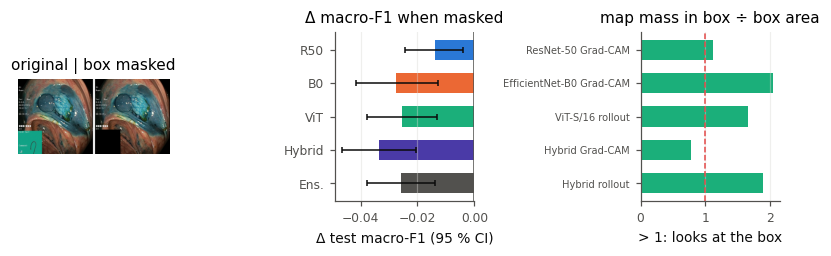

In [26]:
fig, (ax_img, ax_delta, ax_ratio) = plt.subplots(1, 3, figsize=(7.2, 2.4), gridspec_kw={"width_ratios": [1.3, 1.2, 1.2]})
if box_positions:
    k = box_positions[0]
    pair = eval_view(torch.cat([X["test"][k:k + 1], mask_box(X["test"][k:k + 1])])).permute(0, 2, 3, 1).cpu().numpy()
    ax_img.imshow(np.concatenate([pair[0], np.ones((IMG_SIZE, 6, 3)), pair[1]], 1))
ax_img.set_title("original | box masked")
ax_img.axis("off")
d = shortcut_table["Δ macro-F1"].values
yy = np.arange(len(ALL))
ax_delta.barh(yy, d, color=[COLORS[n] for n in shortcut_table.index], height=0.6)
ax_delta.errorbar(d, yy, xerr=[d - shortcut_table["Δ CI low"].values, shortcut_table["Δ CI high"].values - d],
                  fmt="none", ecolor="#0b0b0b", elinewidth=1, capsize=2)
ax_delta.axvline(0, color="#52514e", lw=1)
ax_delta.set_yticks(yy, [SHORT.get(n, "Ens.") for n in shortcut_table.index])
ax_delta.invert_yaxis()
ax_delta.set(title="Δ macro-F1 when masked", xlabel="Δ test macro-F1 (95 % CI)")
if attention_ratio:
    labels_r = list(attention_ratio)
    ax_ratio.barh(range(len(labels_r)), list(attention_ratio.values()), color="#1baf7a", height=0.6)
    ax_ratio.set_yticks(range(len(labels_r)), [l.replace(" attention rollout", " rollout").replace(" (CNN part)", "") for l in labels_r], fontsize=6.5)
    ax_ratio.axvline(1, color="#e34948", lw=1, ls="--")
    ax_ratio.invert_yaxis()
ax_ratio.set(title="map mass in box ÷ box area", xlabel="> 1: looks at the box")
for a in (ax_delta, ax_ratio):
    a.grid(axis="x", alpha=0.4)
plt.tight_layout()
save_figure(fig, "fig8_shortcut_test")

## 14. Critical analysis

### 14.1 Automatic findings
The cell below extracts the key facts from the tables above (so the discussion is always consistent with the run
that produced the figures).

In [27]:
single = [m for m in ORDER if m in MAIN_MODELS]
best, worst = single[0], single[-1]
r = summary
findings = [f"Best single model: {best} (macro-F1 {r.loc[best, 'Test macro-F1']:.3f} "
            f"[{r.loc[best, 'F1 CI low']:.3f}, {r.loc[best, 'F1 CI high']:.3f}]); weakest: {worst} ({r.loc[worst, 'Test macro-F1']:.3f})."]
for a, b in [("ResNet-50", "ViT-S/16"), (HYBRID, "ResNet-50"), ("EfficientNet-B0", "ResNet-50"), (ENSEMBLE, best)]:
    if a == b:
        continue
    _, _, p = mcnemar(preds[a], preds[b])
    findings.append(f"{a} vs {b}: Δ macro-F1 = {r.loc[a, 'Test macro-F1'] - r.loc[b, 'Test macro-F1']:+.3f}, "
                    f"McNemar p = {p:.3g} ({'significant' if p < 0.05 else 'NOT significant'}).")
eff = (r.loc[single, "Test macro-F1"] / r.loc[single, "GMACs"]).idxmax()
fast = r.loc[single, "Train time (s)"].idxmin()
conv = r.loc[single, "Epochs to 95% of best"].idxmin()
findings += [f"Most compute-efficient (F1 per GMAC): {eff}; fastest to train: {fast} ({r.loc[fast, 'Train time (s)']:.0f} s); "
             f"fastest convergence: {conv} ({r.loc[conv, 'Epochs to 95% of best']:.0f} epochs to 95 % of its best).",
             f"Lowest single-image latency: {r.loc[single, 'Latency batch 1 (ms)'].idxmin()} "
             f"({r.loc[single, 'Latency batch 1 (ms)'].min():.2f} ms); real-time threshold ≈ 33 ms.",
             f"Ensemble chosen on validation: {ENSEMBLE} → test macro-F1 {r.loc[ENSEMBLE, 'Test macro-F1']:.3f} at "
             f"{r.loc[ENSEMBLE, 'GMACs']:.2f} GMACs (sum of members)."]
pairs = [(confusion_total[i, j], CLASSES[i], CLASSES[j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j]
findings.append("Top confusions (summed over the 4 models): " + "; ".join(f"{t} → {p} ({n})" for n, t, p in sorted(pairs, reverse=True)[:3]))
hard = pd.DataFrame({m: per_class[m]["F1"] for m in MAIN_MODELS}).mean(axis=1).sort_values()
findings.append("Hardest classes (mean F1 over models): " + ", ".join(f"{c} ({v:.3f})" for c, v in hard.head(3).items()))
s = sensitivity_table["Δ macro-F1 vs. baseline"].sort_values()
findings.append("Sensitivity (largest drops): " + "; ".join(f"{k}: {v:+.3f}" for k, v in s.head(4).items()))
findings.append("Masking the ScopeGuide box: " + "; ".join(f"{SHORT.get(k, 'Ens.')} {v:+.3f}" for k, v in shortcut_table["Δ macro-F1"].items()))
findings.append("Success criterion 1 (all models ≥ 0.90 macro-F1): " + ("met" if r.loc[single, "Test macro-F1"].min() >= 0.90 else "NOT met"))
findings.append("Success criterion 3 (best model loses ≤ 0.02 when masked): " + ("met" if shortcut_table.loc[best, "Δ macro-F1"] >= -0.02 else "NOT met"))
for f in findings:
    print("•", f)
with open(os.path.join(TABLE_DIR, "findings.txt"), "w") as fh:
    fh.write("\n".join(findings))

• Best single model: ViT-S/16 (macro-F1 0.936 [0.923, 0.949]); weakest: Hybrid R50+Transformer (0.906).
• ResNet-50 vs ViT-S/16: Δ macro-F1 = -0.015, McNemar p = 0.0414 (significant).
• Hybrid R50+Transformer vs ResNet-50: Δ macro-F1 = -0.014, McNemar p = 0.0712 (NOT significant).
• EfficientNet-B0 vs ResNet-50: Δ macro-F1 = -0.008, McNemar p = 0.314 (NOT significant).
• Ensemble ViT+Hybrid vs ViT-S/16: Δ macro-F1 = +0.003, McNemar p = 0.629 (NOT significant).
• Most compute-efficient (F1 per GMAC): EfficientNet-B0; fastest to train: Hybrid R50+Transformer (162 s); fastest convergence: ResNet-50 (2 epochs to 95 % of its best).
• Lowest single-image latency: ViT-S/16 (7.20 ms); real-time threshold ≈ 33 ms.
• Ensemble chosen on validation: Ensemble ViT+Hybrid → test macro-F1 0.938 at 9.47 GMACs (sum of members).
• Top confusions (summed over the 4 models): esophagitis → normal-z-line (121); normal-z-line → esophagitis (83); dyed-resection-margins → dyed-lifted-polyps (45)
• Hardest class

### 14.2 Model by model: why it succeeded, why it failed, what it is good for

> The *expected* behaviour of each model was written **before** training, from its architecture. The *observed*
> paragraphs come from the final run (NVIDIA L4, 44.7 min, §11–13). Where the two disagree, the disagreement is
> itself a finding.

**Overview of the final run.** All four models pass success criterion 1 (test macro-F1 ≥ 0.90). **ViT-S/16 is the
best single model** (macro-F1 0.936 [0.923, 0.949]) and the McNemar test says it is significantly better than each
of the other three (p = 0.041 vs. ResNet-50, 0.002 vs. EfficientNet-B0, < 0.001 vs. the hybrid). The three
CNN-based models (ResNet-50 0.921, EfficientNet-B0 0.912, hybrid 0.906) are **not** significantly different from one
another (p = 0.07–0.54). The spread between architectures (0.03 macro-F1) is small compared with the effect of
pretraining (−0.19 to −0.26, §9): on 5,600 images, *what the network was pretrained on* matters more than *how it is built*.

#### ResNet-50 — classic CNN
* **Expected:** data-efficient thanks to the locality bias of convolutions, very stable training, the most mature
  Grad-CAM; possibly limited for classes recognized by global layout.
* **Observed — why it succeeded:** second best single model (0.921, 92.1 % accuracy) and the **fastest to converge**
  (95 % of its best validation F1 after 2 epochs, best epoch 12). Its Grad-CAM maps are the sharpest and are centred on
  the lesion or landmark (the dye, the pylorus opening, the inflamed z-line; Fig. 6). It is also the model that
  **depends least on the ScopeGuide shortcut**: masking the box costs only −0.014 macro-F1, and its Grad-CAM puts about
  as much mass in the box as a uniform map would (ratio 1.12).
* **Observed — why it failed:** the esophagitis ↔ z-line pair (esophagitis recall 0.81; 19 % of esophagitis images
  called z-line), and it is the model that confuses dyed resection margins with dyed polyps the most (9 %). It is also
  the slowest per epoch of the single-branch models (15.4 s) and uses more memory than ViT-S (1.9 GB vs. 1.5 GB) for a
  lower score.
* **Good for:** an interpretable, robust baseline for clinical validation: its explanations are the easiest to show
  to an endoscopist, and it is the least affected by the acquisition artifact.

#### EfficientNet-B0 — efficient CNN
* **Expected:** the best accuracy per parameter and per MAC; not as fast on a GPU as its MAC count suggests.
* **Observed — why it succeeded:** with **4.0 M parameters and 0.38 GMACs** (≈ 1/5 of the parameters and 1/12 of the
  MACs of ViT-S) it reaches 0.912, i.e. 97 % of the best model's macro-F1, and its difference with ResNet-50 is not
  significant (p = 0.31). It has the best **throughput** in batches (0.39 ms/image) and the smallest memory footprint (1.5 GB).
* **Observed — why it failed:** it is the weakest model on the hardest pair (esophagitis F1 0.79, z-line F1 0.80:
  23 % of esophagitis images called z-line): with less capacity it separates fine mucosal differences worst. The
  prediction "fewer MACs ≠ faster" was confirmed in its extreme form: with a **single image** it is the *slowest*
  model (11.3 ms vs. 7.2 ms for ViT-S), because its many small depthwise layers are limited by memory access and kernel
  launches, not by arithmetic. It also leans on the shortcut more than ResNet-50 (−0.028 when masked; its Grad-CAM puts
  2× the expected mass in the box). Finally, §9 shows that the shared fine-tuning learning rate (1e-4) was too
  conservative for it: with 1e-3 it reaches 0.927 (+0.015, significant).
* **Good for:** low-power and edge hardware (CPU, embedded endoscopy processors, mobile), and batched offline
  processing, where its 12× lower compute translates into real savings.

#### ViT-S/16 — pure Transformer
* **Expected:** benefits the most from large-scale pretraining; global context from the first layer; on small data
  everything depends on that pretraining; more diffuse attention maps.
* **Observed — why it succeeded:** best single model (0.936, 93.6 % accuracy) and **the best on the hardest classes**
  (esophagitis F1 0.86, z-line 0.85, esophagitis recall 0.88). It is also the fastest per epoch (9.5 s), the lowest
  single-image latency (7.2 ms) and among the lightest in memory, because 196 tokens × 12 layers map to a few large
  matrix multiplications that tensor cores execute very efficiently. It kept improving until epoch 19 of 20: it is the
  only model that used almost the whole cosine schedule, so its weights benefited from the final low-LR phase.
* **Important caveat — why it may have won:** ViT-S was pretrained on **ImageNet-21k (14 M images)**, the CNNs on
  ImageNet-1k (1.3 M). Part of its advantage is likely the larger pretraining set rather than self-attention itself;
  disentangling the two needs a CNN pretrained on ImageNet-21k (future work).
* **Observed — why it failed:** its attention rollout is diffuse and spread over the image (Fig. 6), which makes it
  harder to explain to a clinician, and its global attention picks up the ScopeGuide box (rollout mass in the box 1.67×
  the uniform level; −0.025 macro-F1 when masked, so it slightly misses success criterion 3). Trained from scratch it
  drops to 0.749 (−0.187): without pretraining it would be a poor choice.
* **Good for:** the best accuracy at a single-model cost, real-time use on a GPU, and as a backbone that can be
  extended to multimodal models (image + report text).

#### Hybrid ResNet-50 + Transformer — built in this project
* **Expected:** combine CNN texture with attention over 196 regions; risk: 4 Transformer layers trained from scratch
  on only 5,600 images, two learning rates to tune.
* **Observed — why it failed (as a single model):** it is the weakest model (0.906), significantly below ViT-S, and
  not significantly different from ResNet-50 (−0.014, p = 0.07). Three reasons, all visible in the results:
  1. **47 % of its parameters (7.6 M) start from random weights**, while it *throws away* the pretrained stage 4 of
     ResNet-50. On this dataset size, replacing pretrained features with randomly initialized ones costs more than the
     extra global modelling gains — the same lesson as the from-scratch runs of §9.
  2. **Unstable optimization of the new layers:** its validation loss rose from 0.30 (epoch 7) to 0.39 (epoch 10) while
     its training loss stayed high (~0.63, vs. ~0.48 for the other models); early stopping kept epoch 6, when the
     cosine learning rate was still at 84 % of its peak. The 10× learning rate (1e-3) for the new layers was probably too high.
  3. It is the model that **depends most on the shortcut** (−0.034 when masked, 12.6 % of predictions on box images
     change). Its CNN part does not look at the box (Grad-CAM ratio 0.79), but its Transformer part does (rollout
     ratio 1.89): attention is what learned the "box anywhere ⇒ colon" cue.
* **Observed — what worked:** it has the **best z-line recall of all models (0.92)** and focused, lesion-centred
  attention maps (Fig. 6, last column). Its errors are the **most different from ViT-S's** (Jaccard overlap 0.33, the
  lowest of all pairs), which is exactly why the validation-based selection chose it as the ensemble partner of ViT-S.
* **Good for:** as a single classifier, not on this dataset size without better initialization. Its design remains a
  natural encoder for segmentation (TransUNet-style, e.g. on Kvasir-SEG) and a strong *complementary* ensemble member.

#### Soft-voting ensemble (ViT-S/16 + Hybrid, chosen on validation)
* **Expected:** the most accurate option when members make different errors; costs the sum of its members.
* **Observed:** the highest test scores (macro-F1 0.938, accuracy 93.8 %), significantly better than ResNet-50,
  EfficientNet-B0 and the hybrid — but **not significantly better than ViT-S alone** (+0.003, p = 0.63: 10 vs. 7
  discordant images) while costing 1.7× the parameters, 2× the MACs and 2.4× the single-image latency. It also inherits
  the shortcut dependence of its members (−0.026 when masked).
* **Good for:** offline second reading of recorded examinations where every error is costly; with this pair of
  members the gain is too small to justify it in real time.

### 14.3 Which model for which situation

| If the priority is… | Use | Because (evidence from this run) |
|---|---|---|
| Maximum accuracy with one model | **ViT-S/16** | 0.936 macro-F1, significantly better than the other three; the ensemble adds only +0.003 (n.s.) for 2× cost |
| Real time next to the endoscope (GPU) | **ViT-S/16** | 7.2 ms per frame at batch 1, far below the 33 ms of a 30 fps video |
| Little hardware / edge device | **EfficientNet-B0** | 4 M parameters, 0.38 GMACs, best batched throughput; only −0.024 macro-F1 vs. ViT-S |
| Interpretability and robustness | **ResNet-50** | Sharpest, lesion-centred Grad-CAM and the smallest dependence on the ScopeGuide artifact (−0.014) |
| Very few labelled images | **The best-pretrained model (here ViT-S, ImageNet-21k)** | Pretraining was the largest effect measured: −0.19 to −0.26 macro-F1 without it |
| Offline second reading | **Ensemble ViT-S + Hybrid** | Highest point estimate (0.938) from the most complementary pair (error overlap 0.33) |

### 14.4 The hardest problem: esophagitis vs. normal z-line
The most frequent confusion for every model is esophagitis ↔ normal z-line (121 + 83 errors summed over the four
models); these are the only two classes with F1 < 0.90 (mean 0.82 and 0.83). Figure 7 shows that the models **look at
the right place** — the Grad-CAM maps are centred on the gastro-esophageal junction — so this is not a localization
failure. The z-line is exactly where esophagitis appears, and mild esophagitis (Los Angeles grade A: small erosions)
looks very much like a normal, slightly irregular z-line; the boundary between the two labels is partly subjective.
The second confusion (dyed resection margins ↔ dyed lifted polyps, both blue) also depends on a subtle cue: whether
the polyp has already been removed. Both pairs are *fine-grained* problems, which is consistent with §9: reducing the
resolution to 64 px costs −0.053 macro-F1.

### 14.5 What the hyperparameter study showed (predictions vs. results)

| Change (EfficientNet-B0 unless stated) | Prediction | Result (Δ macro-F1, 95 % CI) | Verdict |
|---|---|---|---|
| LR 1e-4 → 1e-5 | slower, under-fitted | **−0.107** [−0.129, −0.086]; still improving at epoch 20 | ✔ confirmed |
| LR 1e-4 → 1e-3 | unstable, forgets pretraining | **+0.015** [+0.002, +0.030]; best epoch 10 | ✘ wrong for this CNN: 1e-4 was too conservative for B0 |
| Batch 32 → 128 (same LR) | 4× fewer updates, slower | **−0.014** [−0.029, −0.002] | ✔ confirmed (small) |
| 224 → 64 px | clear drop | **−0.053** [−0.074, −0.034] | ✔ confirmed: fine detail matters (and justifies leaving the 64 px base notebook) |
| No augmentation | more over-fitting | +0.001 [−0.013, +0.013]; lower training loss | ≈ no effect within 20 epochs with pretrained weights and early stopping |
| B0 from scratch | large drop | **−0.259** (0.654) | ✔ confirmed: the largest effect of the study |
| ViT-S from scratch | larger drop than the CNN | **−0.187** (0.749) | ✘ not in absolute terms: both collapse; under the shared fine-tuning LR and early stopping, B0 trained worst from scratch |

The two failed predictions are informative: the optimal learning rate depends on the architecture (a single shared
LR is a simplification of the protocol that slightly under-rates EfficientNet-B0), and "Transformers need pretraining
more than CNNs" could not be confirmed here — **both** families need it on 5,600 images. A fair from-scratch
comparison would need a tuned recipe for each model (higher LR, many more epochs).

### 14.6 Shortcut learning (generalization)
The ScopeGuide box appears in 38 % of the images, in about 98 % of the cecum images and in **none** of the upper-GI classes.
Masking it at test time lowers the macro-F1 of **every** model, with confidence intervals that exclude zero (−0.014 to
−0.034), so all of them learned it to some degree. The models with global attention (ViT-S, the hybrid's Transformer
part) and EfficientNet-B0 look at the box more than a uniform map would (1.7–2.1×), while ResNet-50 does not (1.1×).
The drop is moderate because the box only separates upper from lower GI tract, and the hard decisions happen *within*
each group. Note that the black rectangle is itself a small distribution shift, so these drops are an upper bound of
the dependence. A model deployed in another hospital, with different equipment, could lose part of its accuracy: the
box should be removed or masked **during training**.

## 15. Conclusions, limitations and future work

### Conclusions
1. **All four architectures solve the task well** (test macro-F1 0.906–0.936 on 8 classes; chance = 0.125), and all
   meet the success criterion of macro-F1 ≥ 0.90.
2. **ViT-S/16 is the best single model** (macro-F1 0.936, accuracy 93.6 %), significantly better than ResNet-50,
   EfficientNet-B0 and the hybrid (McNemar p < 0.05), and it is also the fastest at inference on a GPU (7.2 ms per
   image). Its advantage comes at least partly from its larger pretraining set (ImageNet-21k vs. ImageNet-1k for the
   CNNs), so the result should be read as "a well-pretrained Transformer" rather than "attention beats convolution".
3. **Pretraining dominates every architectural choice.** Training from scratch costs −0.19 (ViT-S) to −0.26
   (EfficientNet-B0) macro-F1, an effect 6–9× larger than the whole spread between the four pretrained models (0.03).
   The custom hybrid confirms it from the other side: replacing pretrained layers with randomly initialized
   Transformer layers made it the weakest model, despite its more expressive design.
4. **Efficiency is not one number.** EfficientNet-B0 delivers 97 % of the best macro-F1 with 1/5 of the parameters and
   1/12 of the MACs, and the best batched throughput — yet it has the *highest* single-image latency on the GPU.
   The right model depends on the deployment (batched offline vs. frame-by-frame, GPU vs. edge device).
5. **The ensemble is the most accurate but not worth its cost here:** ViT-S + Hybrid reaches 0.938, an improvement
   over ViT-S alone that is not significant (p = 0.63), for twice the compute. Its members were chosen because their
   errors overlap least (Jaccard 0.33), which is the property that makes ensembles work.
6. **Remaining errors are fine-grained, not localization errors.** Esophagitis vs. normal z-line accounts for most
   mistakes of every model; the interpretability maps show the models look at the gastro-esophageal junction, where the
   difference between the two labels is subtle and partly subjective.
7. **Every model partially learned a dataset shortcut.** The ScopeGuide box (present only in colonoscopies) lowers
   macro-F1 by 0.014–0.034 when masked. ResNet-50 relies on it the least; the models with global attention rely on it
   more. Reported accuracies on Kvasir should be read with this bias in mind.

### Limitations
* **Single training seed.** The confidence intervals capture the variability due to the particular test images, not
  the variability due to training randomness (initialization, batch order). Small differences between models should
  be read together with the McNemar tests.
* **Unequal pretraining data.** ViT-S was pretrained on ImageNet-21k and the CNNs on ImageNet-1k, which confounds
  architecture and pretraining in the main comparison.
* **One shared learning rate.** §9 shows that 1e-4 was too conservative for EfficientNet-B0 (1e-3 gives +0.015), and the
  hybrid's new layers were probably trained with too high a rate; per-model tuning on the validation set could change
  the ranking of the three CNN-based models.
* **One dataset, no external validation.** All images come from one hospital and one type of equipment; the
  ScopeGuide analysis shows how dataset-specific cues can inflate the scores.
* **Early stopping cuts the cosine schedule** before its low-learning-rate phase (all models except ViT-S stopped
  between epochs 10 and 19).
* **Sensitivity analysis on one model, one factor at a time.** Interactions between hyperparameters (e.g. batch size ×
  learning rate) were not explored, and the from-scratch runs used the fine-tuning recipe.
* **Masking test.** The black rectangle is itself a small distribution shift, so the measured drops are an upper bound
  of the shortcut dependence.

### Future work
* **Disentangle architecture and pretraining:** compare with CNNs pretrained on ImageNet-21k (e.g. BiT ResNet-50) or
  with all models pretrained self-supervised on the same data.
* **Self-supervised pretraining on endoscopy** (DINO, MAE) using the 100k+ unlabelled frames of HyperKvasir, to give
  every model domain-specific features.
* **A better-initialized hybrid:** initialize its Transformer layers from ViT-S weights, use a lower learning rate for
  them, or use a fully pretrained hybrid (e.g. R26+ViT-S AugReg) to test the hybrid idea without the initialization handicap.
* **Remove the shortcut during training** (mask or inpaint the ScopeGuide box) and validate on other centres or on
  HyperKvasir; several seeds for training-variance estimates.
* **Fine-grained esophagitis grading:** higher input resolution (the 64 px run shows detail matters) and, if available,
  Los Angeles grade labels instead of a binary esophagitis/normal distinction.
* **Distillation** of the ensemble into a single EfficientNet-B0 for real-time, low-power use; **segmentation** with
  the hybrid as a TransUNet-style encoder on Kvasir-SEG; **multimodal** models combining the image with the report.

### References
1. K. Pogorelov et al., "Kvasir: A multi-class image dataset for computer aided gastrointestinal disease detection," *Proc. ACM MMSys*, 2017.
2. K. He, X. Zhang, S. Ren, J. Sun, "Deep residual learning for image recognition," *CVPR*, 2016.
3. M. Tan, Q. Le, "EfficientNet: Rethinking model scaling for convolutional neural networks," *ICML*, 2019.
4. A. Dosovitskiy et al., "An image is worth 16x16 words: Transformers for image recognition at scale," *ICLR*, 2021.
5. A. Steiner et al., "How to train your ViT? Data, augmentation, and regularization in vision transformers," *TMLR*, 2022.
6. J. Chen et al., "TransUNet: Transformers make strong encoders for medical image segmentation," arXiv:2102.04306, 2021.
7. R. R. Selvaraju et al., "Grad-CAM: Visual explanations from deep networks via gradient-based localization," *ICCV*, 2017.
8. S. Abnar, W. Zuidema, "Quantifying attention flow in transformers," *ACL*, 2020.
9. R. Geirhos et al., "Shortcut learning in deep neural networks," *Nature Machine Intelligence*, 2020.
10. I. Loshchilov, F. Hutter, "Decoupled weight decay regularization," *ICLR*, 2019; "SGDR: Stochastic gradient descent with warm restarts," *ICLR*, 2017.
11. P. Goyal et al., "Accurate, large minibatch SGD: Training ImageNet in 1 hour," arXiv:1706.02677, 2017.
12. C. Szegedy et al., "Rethinking the Inception architecture for computer vision" (label smoothing), *CVPR*, 2016.
13. T. G. Dietterich, "Approximate statistical tests for comparing supervised classification learning algorithms," *Neural Computation*, 1998.
14. H. Borgli et al., "HyperKvasir, a comprehensive multi-class image and video dataset for gastrointestinal endoscopy," *Scientific Data*, 2020.
15. A. Kolesnikov et al., "Big Transfer (BiT): General visual representation learning," *ECCV*, 2020.

In [28]:
# Package the results (figures + tables + run histories, without the large checkpoints) for the paper and slides
archive = os.path.join(PROJECT_DIR, os.path.basename(RESULTS_DIR) + ".zip")
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as z:
    for folder, _, files in os.walk(RESULTS_DIR):
        for f in files:
            if not f.endswith(".pt"):
                z.write(os.path.join(folder, f), os.path.relpath(os.path.join(folder, f), RESULTS_DIR))
print(f"Results archive: {archive} ({os.path.getsize(archive) / 2**20:.1f} MB, checkpoints excluded)")
print(f"Figures: {sorted(os.listdir(FIG_DIR))}")
print(f"Total notebook time: {(time.time() - NOTEBOOK_START) / 60:.1f} min on {GPU_NAME}")

Results archive: /content/drive/MyDrive/kvasir_dl_final/results.zip (27.0 MB, checkpoints excluded)
Figures: ['fig0_lr_schedule.pdf', 'fig0_lr_schedule.png', 'fig1_performance_ci.pdf', 'fig1_performance_ci.png', 'fig2_convergence.pdf', 'fig2_convergence.png', 'fig3_performance_vs_cost.pdf', 'fig3_performance_vs_cost.png', 'fig4_per_class_f1.pdf', 'fig4_per_class_f1.png', 'fig5_confusion_matrices.pdf', 'fig5_confusion_matrices.png', 'fig6_interpretability.pdf', 'fig6_interpretability.png', 'fig7_failure_cases.pdf', 'fig7_failure_cases.png', 'fig8_shortcut_test.pdf', 'fig8_shortcut_test.png', 'fig_augmentation_examples.pdf', 'fig_augmentation_examples.png', 'fig_dataset_examples.pdf', 'fig_dataset_examples.png', 'fig_scopeguide_bias.pdf', 'fig_scopeguide_bias.png', 'fig_sensitivity.pdf', 'fig_sensitivity.png']
Total notebook time: 44.7 min on NVIDIA L4
